# Projet AI pour la BI — Partie 1 : Data Preparation & Feature Engineering

*Documentation complète (contexte, décisions, résultats, limites) : voir [`README.md`](../README.md) à la racine du projet.*

## Étape 0 — Configuration et chargement

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['axes.titleweight'] = 'bold'

SEED = 42
np.random.seed(SEED)

DATA   = Path('..') / 'data'
MAIN   = DATA / 'fichiers principaux'
ANNEXE = DATA / 'annexe'
OUT    = Path('outputs')
OUT.mkdir(exist_ok=True)
print('Versions -> pandas', pd.__version__, '| numpy', np.__version__)

Versions -> pandas 2.3.3 | numpy 2.3.0


In [2]:
# Chargement BRUT : aucun typage forcé, pour observer les données telles qu'elles ont été reçues
FILES = {
    'machine':    'gm_machineinstance.csv',
    'reparation': 'gm_reparation.csv',
    'appel':      'gm_reparationappel.csv',
    'entretien':  'gm_entretien.csv',
    'preventif':  'gm_preventif_machine.csv',
    'historique': 'gm_historiquemachineendroit.csv',
    'mouvement':  'gm_mouvementmachine.csv',
    'action':     'gm_action.csv',
    'nature':     'gm_naturepanne.csv',
    'probleme':   'gm_problemepanne.csv',
    'classe':     'gm_classemachine.csv',
    'categorie':  'gm_categoriemachine.csv',
    'endroit':    'gm_endroitmachine.csv',
}
raw    = {k: pd.read_csv(MAIN / f, low_memory=False) for k, f in FILES.items()}
annexe = {p.stem: pd.read_csv(p, low_memory=False) for p in sorted(ANNEXE.glob('*.csv'))}
print(f'{len(raw)} fichiers principaux et {len(annexe)} fichiers annexes chargés.')

13 fichiers principaux et 11 fichiers annexes chargés.


In [3]:
# ---------- Fonctions utilitaires réutilisées dans tout le notebook ----------
def to_dt(s):
    # Conversion date robuste : l'export mélange plusieurs précisions (secondes, millisecondes, date seule)
    return pd.to_datetime(s, format='ISO8601', errors='coerce')

def profile(df):
    # Profil colonne par colonne : type, valeurs manquantes, cardinalité, modalité dominante
    out = pd.DataFrame({
        'type': df.dtypes.astype(str),
        'non_nuls': df.notna().sum(),
        'manquants_%': (df.isna().mean() * 100).round(1),
        'nb_uniques': df.nunique(),
    })
    top = {}
    for c in df.columns:
        vc = df[c].value_counts(normalize=True)
        top[c] = f'{str(vc.index[0])[:28]} ({vc.iloc[0]*100:.1f}%)' if len(vc) else '—'
    out['modalité_dominante'] = pd.Series(top)
    return out

def norm_txt(s):
    # Harmonisation des libellés : espaces superflus supprimés, majuscules
    return s.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).str.upper()

def pct(x, n):
    return round(100 * x / n, 2) if n else 0.0

## Étape 1 — Compréhension et exploration des données

### 1.1 Inventaire des fichiers : taille, colonnes, qualité globale

In [4]:
inv = []
for k, df in raw.items():
    inv.append({
        'table': k, 'fichier': FILES[k], 'lignes': len(df), 'colonnes': df.shape[1],
        'taille_Mo': round((MAIN / FILES[k]).stat().st_size / 1e6, 2),
        'cols_100%_vides': int(df.isna().all().sum()),
        'manquants_%_global': round(df.isna().mean().mean() * 100, 1),
        'doublons_exacts': int(df.duplicated().sum()),
    })
inventaire = pd.DataFrame(inv).set_index('table')
inventaire

,fichier,lignes,colonnes,taille_Mo,cols_100%_vides,manquants_%_global,doublons_exacts
table,,,,,,,
machine,gm_machineinstance.csv,1649,42,0.36,8,30.8,0
reparation,gm_reparation.csv,32772,42,8.47,3,33.1,0
appel,gm_reparationappel.csv,32331,14,3.10,4,28.8,0
entretien,gm_entretien.csv,65173,18,7.95,2,23.2,0
preventif,gm_preventif_machine.csv,4109,16,0.41,5,47.8,0
historique,gm_historiquemachineendroit.csv,15191,7,0.68,2,28.6,0
mouvement,gm_mouvementmachine.csv,15191,6,0.57,0,16.5,0
action,gm_action.csv,62,5,0.00,2,40.0,0
nature,gm_naturepanne.csv,40,3,0.00,0,4.2,0


In [5]:
pd.DataFrame([{'fichier': k, 'lignes': len(d), 'colonnes': d.shape[1],
               'cols_100%_vides': int(d.isna().all().sum())} for k, d in annexe.items()]).set_index('fichier')

,lignes,colonnes,cols_100%_vides
fichier,,,
gm_actionclassmachine,432,6,0
gm_categoriepiece,34,4,0
gm_entreemagasinpiece,97,19,4
gm_etatmachine,5,4,0
gm_famillepiece,9,4,0
gm_fichmouvement,4428,10,4
gm_moteurmachine,2,2,0
gm_piece,229,14,4
gm_piececlasses,2261,2,0


### 1.2 Structure détaillée des tables principales

In [6]:
for t in ['machine', 'reparation']:
    print(f'\n=== {t.upper()}  {raw[t].shape}')
    display(profile(raw[t]))


=== MACHINE  (1649, 42)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id_machine_instance,int64,1649,0.0,1649,814 (0.1%)
nom_machine,object,1649,0.0,129,PIQUEUSE SIMPLE (19.1%)
imm_unique,object,1648,0.1,1648,I813 (0.1%)
num_tete,float64,0,100.0,0,—
code_local,object,1649,0.0,1649,FD5616 (0.1%)
date_achat,object,1649,0.0,439,2019-07-20 00:00:00 (14.4%)
date_declaration,object,1054,36.1,196,2019-07-20 00:00:00 (17.9%)
cout,float64,112,93.2,43,2.3 (13.4%)
numero,float64,1642,0.4,1641,1505.0 (0.1%)
remarque,object,40,97.6,21,manque ecartement (40.0%)



=== REPARATION  (32772, 42)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id_reparation,int64,32772,0.0,32772,1694072 (0.0%)
dateheurerep,object,32554,0.7,31856,2023-03-10 11:22:03.25 (0.1%)
daterep,object,32554,0.7,25629,2023-12-01 00:00:00 (0.1%)
dureerep,int64,32772,0.0,251,0 (19.8%)
datearretchaine,object,32772,0.0,32056,2023-03-10 11:18:12.672 (0.1%)
dureearret,float64,32594,0.5,388,0.0 (11.0%)
description,object,231,99.3,3,modif (98.7%)
datefin,object,32772,0.0,32549,2025-06-23 00:00:00 (0.0%)
id_naturepnne,float64,32590,0.6,32,2.0 (21.0%)
id_endroit,float64,32770,0.0,60,799314.0 (5.1%)


In [7]:
for t in ['appel', 'entretien', 'preventif', 'historique', 'mouvement']:
    print(f'\n=== {t.upper()}  {raw[t].shape}')
    display(profile(raw[t]))


=== APPEL  (32331, 14)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id_appel,int64,32331,0.0,32331,867083 (0.0%)
date_appel,object,32331,0.0,32331,2022-03-22 09:33:42.918 (0.0%)
date_consult,object,31841,1.5,31841,2022-03-21 13:12:24.832 (0.0%)
date_fin_rep,float64,0,100.0,0,—
cloture,object,32331,0.0,2,t (100.0%)
reference,float64,0,100.0,0,—
id_matricule,int64,32331,0.0,75,319 (9.4%)
id_machine_instance,int64,32331,0.0,1312,1095 (0.6%)
id_naturepnne,float64,0,100.0,0,—
id_endroit,int64,32331,0.0,56,799314 (5.3%)



=== ENTRETIEN  (65173, 18)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id_entretien,int64,65173,0.0,65173,1022252 (0.0%)
date_heure_debut,object,65173,0.0,29253,2022-08-01 12:00:00 (0.5%)
date_debut,object,65173,0.0,1030,2025-09-01 00:00:00 (1.2%)
duree,int64,65173,0.0,36,5 (53.0%)
heuresactuelles,float64,5,100.0,5,76095.0 (20.0%)
moisactuels,float64,5,100.0,4,8.0 (40.0%)
faite,object,65173,0.0,2,f (100.0%)
id_action,int64,65173,0.0,30,977115 (59.6%)
id_machine_instance,int64,65173,0.0,1330,1080923 (1.7%)
dureearret,float64,65172,0.0,14,0.0 (96.5%)



=== PREVENTIF  (4109, 16)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id,int64,4109,0.0,4109,963137 (0.0%)
dernier_entretien_jour,object,4109,0.0,434,2025-12-05 00:00:00 (7.8%)
prochain_entretien_jour,object,3556,13.5,369,2026-02-27 00:00:00 (7.1%)
frequence_jour,int64,4109,0.0,16,28 (33.9%)
frequence_autre,float64,0,100.0,0,—
dernier_entretien_autre,float64,0,100.0,0,—
prochain_entretien_autre,float64,0,100.0,0,—
faite,object,4109,0.0,2,f (63.8%)
description,object,3,99.9,1,1/an (100.0%)
avant_dernier,object,3465,15.7,423,2025-11-24 00:00:00 (9.4%)



=== HISTORIQUE  (15191, 7)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id_historique_endroit,int64,15191,0.0,15191,786659 (0.0%)
date_lecture,object,15191,0.0,864,2024-10-02 00:00:00 (2.4%)
actif,object,15191,0.0,1,f (100.0%)
nom_machine,float64,0,100.0,0,—
site_machine,float64,0,100.0,0,—
id_machine_instance,int64,15191,0.0,1546,791753 (0.3%)
id_endroit,int64,15191,0.0,66,13 (11.3%)



=== MOUVEMENT  (15191, 6)


,type,non_nuls,manquants_%,nb_uniques,modalité_dominante
id,int64,15191,0.0,15191,786660 (0.0%)
raison,object,1849,87.8,86,BESOIN (31.7%)
end_act,float64,14616,3.8,62,13.0 (12.6%)
destination,int64,15191,0.0,66,13 (11.3%)
fiche,float64,14079,7.3,4144,1120805.0 (1.0%)
machine,int64,15191,0.0,1546,791753 (0.3%)


In [8]:
# Référentiels : aperçu direct
for t in ['action', 'nature', 'probleme', 'classe', 'categorie', 'endroit']:
    print(f'\n=== {t.upper()}  {raw[t].shape}')
    display(raw[t].head(4))


=== ACTION  (62, 5)


,id_action,nom_action,consigne,observations,actif
0,1,Controle tension courroie,NaN,NaN,t
1,2,Verification niveau d'huile + Controle fuite d'huile,NaN,NaN,t
2,3,Vidange,NaN,NaN,t
3,4,Nettoyage Machine,NaN,NaN,t



=== NATURE  (40, 3)


,id_naturepanne,lib_naturepanne,id_categorie
0,800039,REGLAGE LAME,NaN
1,800064,PANNE MOTEUR,NaN
2,800065,PANNE ELECTRIQUE,NaN
3,920330,PANNE NON ELIGIBLE,NaN



=== PROBLEME  (32, 3)


,id_naturepanne,lib_naturepanne,id_categorie
0,783150,CASSE AIGUILLE,35
1,783151,CASSE FIL,35
2,783152,PROBLEME RASAGE,35
3,783153,POINT SAUTE,35


... (2 outputs left out)


=== CATEGORIE  (11, 2)


,id_categorie,lib_categorie
0,34,Machine De Coupe
1,35,Machine A Coudre
2,36,Machine A Souder
3,37,Machine De Repassage



=== ENDROIT  (68, 8)


,id_endroit,nom_endroit,id_chaine,id_site,depannage,id_matricule,nature,preventifexclu
0,15,Coupe ENFAVET INTER,NaN,1.0,f,NaN,Coupe,f
1,1433934,Parc machine INTER,NaN,1.0,f,NaN,Parc,t
2,874413,Parc dépannage inter,NaN,1.0,t,NaN,Parc,t
3,874414,Parc dépannage PLUS,NaN,4.0,t,NaN,Parc,t


### 1.3 Granularité : que représente une ligne ?

In [9]:
PK = {'machine': 'id_machine_instance', 'reparation': 'id_reparation', 'appel': 'id_appel',
      'entretien': 'id_entretien', 'preventif': 'id', 'historique': 'id_historique_endroit',
      'mouvement': 'id', 'action': 'id_action', 'nature': 'id_naturepanne',
      'probleme': 'id_naturepanne', 'classe': 'id_classe_machine', 'categorie': 'id_categorie',
      'endroit': 'id_endroit'}
GRAIN = {
    'machine':    '1 machine physique du parc (référentiel, état au moment de l\'extraction)',
    'reparation': '1 intervention corrective : arrêt -> prise en charge -> fin',
    'appel':      '1 signalement de panne par la production (précède la réparation)',
    'entretien':  '1 occurrence d\'action de maintenance préventive sur une machine',
    'preventif':  '1 couple (machine, action préventive) : fréquence + dernière/prochaine échéance',
    'historique': '1 lecture datée de l\'emplacement d\'une machine',
    'mouvement':  '1 déplacement de machine (origine -> destination), sans date',
    'action':     '1 type d\'action de maintenance', 'nature': '1 nature de panne / d\'intervention',
    'probleme':   '1 problème constaté', 'classe': '1 modèle de machine',
    'categorie':  '1 grande catégorie de machine', 'endroit': '1 emplacement (ligne, parc, atelier)'}
pd.DataFrame([{'table': t, 'clé primaire': c, 'unique': raw[t][c].is_unique,
               'nulls': int(raw[t][c].isna().sum()), 'une ligne =': GRAIN[t]} for t, c in PK.items()])

,table,clé primaire,unique,nulls,une ligne =
0,machine,id_machine_instance,True,0,"1 machine physique du parc (référentiel, état au moment de l'extra..."
1,reparation,id_reparation,True,0,1 intervention corrective : arrêt -> prise en charge -> fin
2,appel,id_appel,True,0,1 signalement de panne par la production (précède la réparation)
3,entretien,id_entretien,True,0,1 occurrence d'action de maintenance préventive sur une machine
4,preventif,id,True,0,"1 couple (machine, action préventive) : fréquence + dernière/proch..."
5,historique,id_historique_endroit,True,0,1 lecture datée de l'emplacement d'une machine
6,mouvement,id,True,0,"1 déplacement de machine (origine -> destination), sans date"
7,action,id_action,True,0,1 type d'action de maintenance
8,nature,id_naturepanne,True,0,1 nature de panne / d'intervention
9,probleme,id_naturepanne,True,0,1 problème constaté


In [10]:
# Clé composite du préventif : le couple (machine, action) est-il unique ?
print('preventif (id_machine_instance, id_action) unique :',
      not raw['preventif'].duplicated(['id_machine_instance', 'id_action']).any())

preventif (id_machine_instance, id_action) unique : True


### 1.4 Clés de liaison et relations entre fichiers

In [11]:
FK = [('machine', 'id_class_machine', 'classe', 'id_classe_machine'),
      ('machine', 'id_categ_machine', 'categorie', 'id_categorie'),
      ('machine', 'id_endroit', 'endroit', 'id_endroit'),
      ('reparation', 'id_machine_instance', 'machine', 'id_machine_instance'),
      ('reparation', 'id_naturepnne', 'nature', 'id_naturepanne'),
      ('reparation', 'id_probleme', 'probleme', 'id_naturepanne'),
      ('reparation', 'id_endroit', 'endroit', 'id_endroit'),
      ('appel', 'id_machine_instance', 'machine', 'id_machine_instance'),
      ('appel', 'id_problemepanne', 'probleme', 'id_naturepanne'),
      ('appel', 'id_reparation', 'reparation', 'id_reparation'),
      ('entretien', 'id_machine_instance', 'machine', 'id_machine_instance'),
      ('entretien', 'id_action', 'action', 'id_action'),
      ('preventif', 'id_machine_instance', 'machine', 'id_machine_instance'),
      ('preventif', 'id_action', 'action', 'id_action'),
      ('historique', 'id_machine_instance', 'machine', 'id_machine_instance'),
      ('historique', 'id_endroit', 'endroit', 'id_endroit'),
      ('mouvement', 'machine', 'machine', 'id_machine_instance'),
      ('mouvement', 'destination', 'endroit', 'id_endroit')]
rows = []
for s, c, t, tc in FK:
    k = raw[s][c].dropna()
    per_key = k.value_counts()
    rows.append({'source': f'{s}.{c}', 'cible': f'{t}.{tc}',
                 'manquants_%': round(raw[s][c].isna().mean() * 100, 1),
                 'correspondance_%': round(k.isin(raw[t][tc]).mean() * 100, 2),
                 'cardinalité': '1–1' if per_key.max() == 1 else 'N–1',
                 'max_lignes_par_clé': int(per_key.max()),
                 'couverture_cible_%': round(raw[t][tc].isin(k).mean() * 100, 1)})
relations = pd.DataFrame(rows)
relations

,source,cible,manquants_%,correspondance_%,cardinalité,max_lignes_par_clé,couverture_cible_%
0,machine.id_class_machine,classe.id_classe_machine,0.0,100.0,N–1,77,94.7
1,machine.id_categ_machine,categorie.id_categorie,0.2,100.0,N–1,1442,100.0
2,machine.id_endroit,endroit.id_endroit,3.9,100.0,N–1,170,88.2
3,reparation.id_machine_instance,machine.id_machine_instance,0.0,100.0,N–1,185,80.0
4,reparation.id_naturepnne,nature.id_naturepanne,0.6,100.0,N–1,6837,80.0
5,reparation.id_probleme,probleme.id_naturepanne,0.6,100.0,N–1,8527,90.6
6,reparation.id_endroit,endroit.id_endroit,0.0,100.0,N–1,1672,88.2
7,appel.id_machine_instance,machine.id_machine_instance,0.0,100.0,N–1,184,79.6
8,appel.id_problemepanne,probleme.id_naturepanne,0.0,100.0,N–1,8448,90.6
9,appel.id_reparation,reparation.id_reparation,1.3,100.0,1–1,1,97.4


### 1.5 Périodes temporelles couvertes

In [12]:
DATE_COLS = {'machine': ['date_achat', 'date_declaration'],
             'reparation': ['datearretchaine', 'dateheurerep', 'datefinmecanicien', 'datefin',
                            'datearretchaine_withouthour', 'date_fin_mecanicien'],
             'appel': ['date_appel', 'date_consult'],
             'entretien': ['date_debut', 'date_prevue'],
             'preventif': ['dernier_entretien_jour', 'prochain_entretien_jour', 'avant_dernier', 'date_affectation'],
             'historique': ['date_lecture']}
cov = []
for t, cols in DATE_COLS.items():
    for c in cols:
        d = to_dt(raw[t][c])
        cov.append({'table': t, 'colonne': c, 'valides': int(d.notna().sum()),
                    'manquants_%': round(d.isna().mean() * 100, 1), 'min': d.min(), 'max': d.max()})
couverture = pd.DataFrame(cov)
couverture

,table,colonne,valides,manquants_%,min,max
0,machine,date_achat,1649,0.0,1994-11-26 00:00:00.000,2026-02-10 00:00:00.000
1,machine,date_declaration,1054,36.1,1994-11-26 00:00:00.000,2024-12-19 00:00:00.000
2,reparation,datearretchaine,32772,0.0,2021-11-13 11:45:06.068,2026-03-05 12:37:59.296
3,reparation,dateheurerep,32554,0.7,2021-11-13 11:45:26.055,2026-03-05 12:44:23.388
4,reparation,datefinmecanicien,32346,1.3,2021-11-13 11:53:16.876,2026-03-05 13:02:23.002
5,reparation,datefin,32772,0.0,2021-11-13 11:53:16.876,2026-03-05 13:37:25.794
6,reparation,datearretchaine_withouthour,32585,0.6,2021-11-13 00:00:00.000,2026-03-05 00:00:00.000
7,reparation,date_fin_mecanicien,6792,79.3,2021-11-13 00:00:00.000,2022-11-17 00:00:00.000
8,appel,date_appel,32331,0.0,2021-11-13 11:45:06.068,2026-03-05 13:37:43.882
9,appel,date_consult,31841,1.5,2021-11-13 11:45:26.055,2026-03-05 13:38:56.762


In [13]:
# Date d'extraction de l'ERP : dernier événement réellement OBSERVÉ (arrêt, appel, lecture d'emplacement)
DATE_EXTRACTION = max(to_dt(raw['reparation'].datearretchaine).max(),
                      to_dt(raw['appel'].date_appel).max(),
                      to_dt(raw['historique'].date_lecture).max()).normalize()
FIN_OBS = DATE_EXTRACTION + pd.Timedelta(days=1)   # borne exclusive de la période observée
print('Date d\'extraction retenue :', DATE_EXTRACTION.date())

Date d'extraction retenue : 2026-03-05


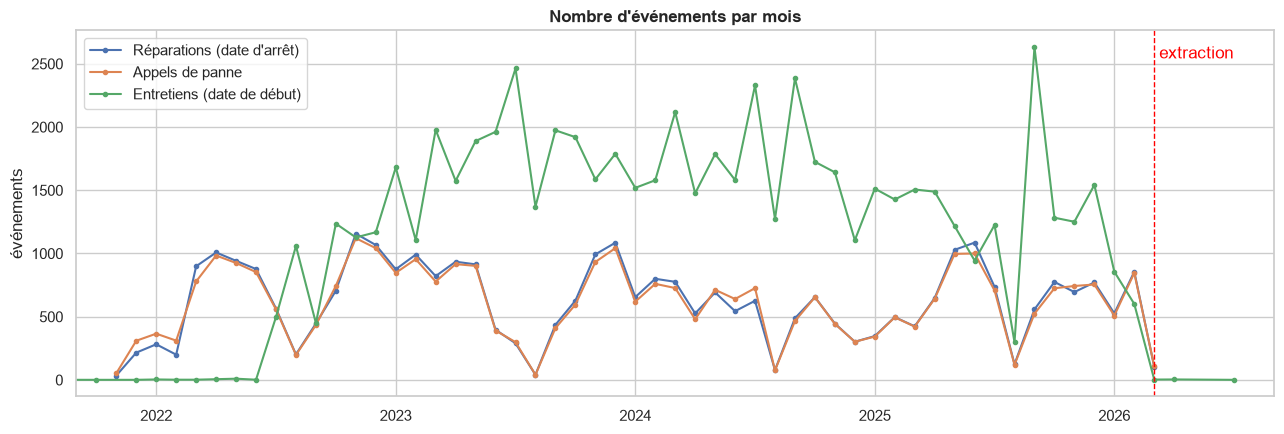

In [14]:
# Activité mensuelle des 3 tables d'événements
fig, ax = plt.subplots(figsize=(13, 4.5))
series = {'Réparations (date d\'arrêt)': to_dt(raw['reparation'].datearretchaine),
          'Appels de panne': to_dt(raw['appel'].date_appel),
          'Entretiens (date de début)': to_dt(raw['entretien'].date_debut)}
for lab, s in series.items():
    s.dt.to_period('M').value_counts().sort_index().to_timestamp().plot(ax=ax, label=lab, marker='.')
ax.axvline(DATE_EXTRACTION, color='red', ls='--', lw=1)
ax.text(DATE_EXTRACTION, ax.get_ylim()[1] * 0.92, ' extraction', color='red')
ax.set_title('Nombre d\'événements par mois'); ax.set_xlabel(''); ax.set_ylabel('événements'); ax.legend()
ax.set_xlim(pd.Timestamp('2021-09-01'), pd.Timestamp('2026-09-01'))
plt.tight_layout(); plt.show()

### 1.6 Variables quantitatives et catégorielles ; unité des durées

In [15]:
TYPES_VAR = {
    'machine':    {'quantitatives': ['cout', 'cout_total', 'cout_reparation', 'cout_entretien'],
                   'catégorielles': ['nom_machine', 'etat', 'type', 'moteur', 'nom_methode', 'fabricant', 'classe', 'chaine'],
                   'dates': ['date_achat', 'date_declaration']},
    'reparation': {'quantitatives': ['dureerep', 'dureearret', 'dureeattente', 'duree_attente', 'nombre_piece'],
                   'catégorielles': ['categorie_reparation', 'changement', 'a_probleme', 'cloture', 'type', 'chaine'],
                   'dates': ['datearretchaine', 'dateheurerep', 'datefinmecanicien', 'datefin']},
    'entretien':  {'quantitatives': ['duree', 'dureearret'], 'catégorielles': ['faite', 'chaine'],
                   'dates': ['date_debut', 'date_prevue']},
    'preventif':  {'quantitatives': ['frequence_jour'], 'catégorielles': ['faite'],
                   'dates': ['dernier_entretien_jour', 'prochain_entretien_jour']}}
pd.DataFrame([{'table': t, 'type': k, 'variables': ', '.join(v)} for t, d in TYPES_VAR.items() for k, v in d.items()])

,table,type,variables
0,machine,quantitatives,"cout, cout_total, cout_reparation, cout_entretien"
1,machine,catégorielles,"nom_machine, etat, type, moteur, nom_methode, fabricant, classe, c..."
2,machine,dates,"date_achat, date_declaration"
3,reparation,quantitatives,"dureerep, dureearret, dureeattente, duree_attente, nombre_piece"
4,reparation,catégorielles,"categorie_reparation, changement, a_probleme, cloture, type, chaine"
5,reparation,dates,"datearretchaine, dateheurerep, datefinmecanicien, datefin"
6,entretien,quantitatives,"duree, dureearret"
7,entretien,catégorielles,"faite, chaine"
8,entretien,dates,"date_debut, date_prevue"
9,preventif,quantitatives,frequence_jour


In [16]:
r0 = raw['reparation']
t_arret, t_rep = to_dt(r0.datearretchaine), to_dt(r0.dateheurerep)
t_finmeca, t_fin = to_dt(r0.datefinmecanicien), to_dt(r0.datefin)
minutes = lambda a, b: (b - a).dt.total_seconds() / 60
checks = {'dureeattente  ~ dateheurerep - datearretchaine': (minutes(t_arret, t_rep), r0.dureeattente),
          'dureerep      ~ datefinmecanicien - dateheurerep': (minutes(t_rep, t_finmeca), r0.dureerep),
          'dureearret    ~ datefin - datearretchaine':        (minutes(t_arret, t_fin), r0.dureearret)}
pd.DataFrame([{'hypothèse (en minutes)': k, 'concordance ±2 min (%)': round(((a - b).abs() <= 2).mean() * 100, 1)}
              for k, (a, b) in checks.items()])

,hypothèse (en minutes),concordance ±2 min (%)
0,dureeattente ~ dateheurerep - datearretchaine,86.7
1,dureerep ~ datefinmecanicien - dateheurerep,91.9
2,dureearret ~ datefin - datearretchaine,86.5


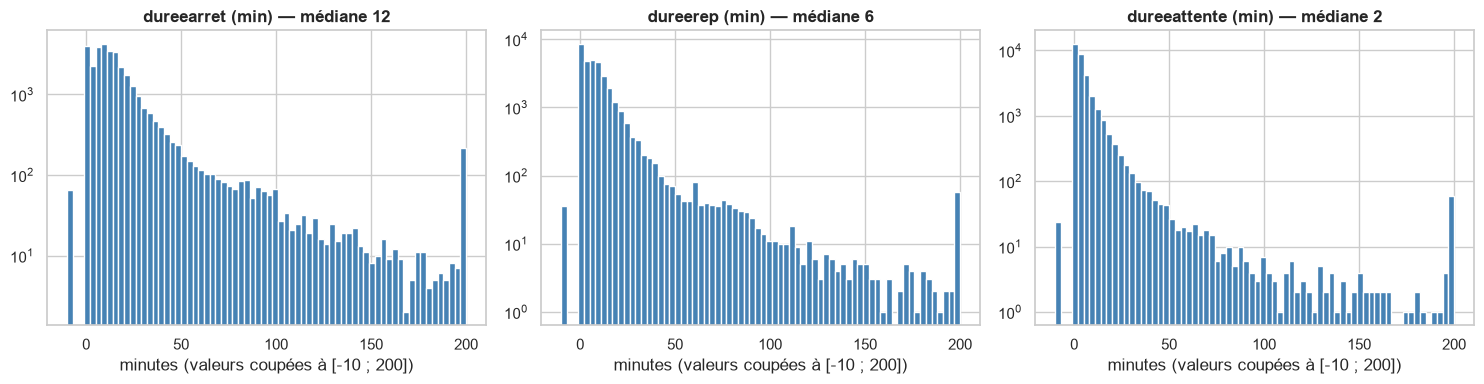

,dureearret,dureerep,dureeattente
count,32594.0,32772.0,32250.0
mean,19.2,10.0,5.7
std,34.7,21.4,18.3
min,-533.0,-543.0,-522.0
1%,0.0,0.0,0.0
25%,6.0,1.0,1.0
50%,12.0,6.0,2.0
75%,21.0,12.0,6.0
90%,39.0,21.0,13.0
99%,155.0,84.0,51.0


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['dureearret', 'dureerep', 'dureeattente']):
    v = r0[c].dropna()
    ax.hist(v.clip(-10, 200), bins=70, color='steelblue')
    ax.set_yscale('log'); ax.set_title(f'{c} (min) — médiane {v.median():.0f}')
    ax.set_xlabel('minutes (valeurs coupées à [-10 ; 200])')
plt.tight_layout(); plt.show()
r0[['dureearret', 'dureerep', 'dureeattente']].describe(percentiles=[.01, .25, .5, .75, .9, .99]).round(1)

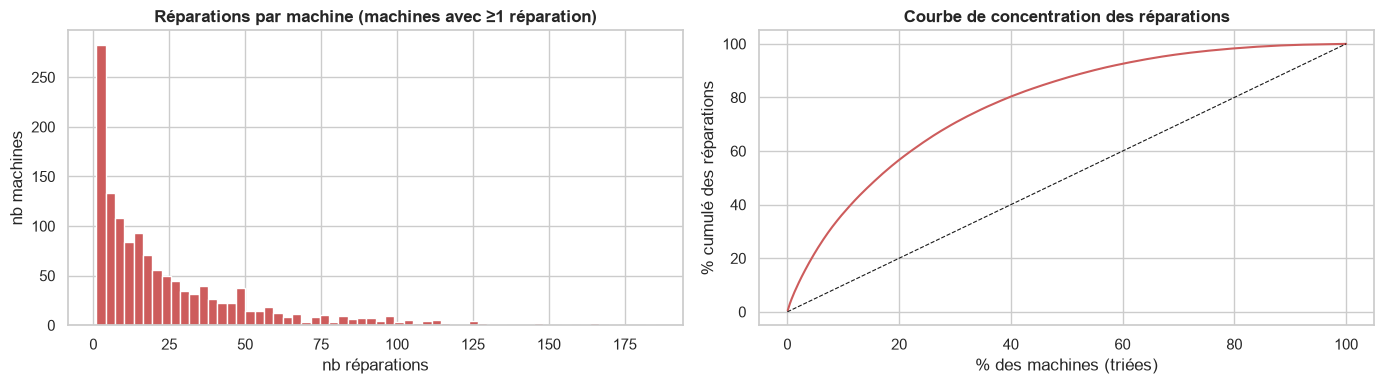

Médiane = 15 réparations/machine ; max = 185 ; les 10 % de machines les plus touchées concentrent 36.6 % des réparations.


In [18]:
# Concentration des pannes : combien de réparations par machine ?
rep_par_machine = r0.groupby('id_machine_instance').size().sort_values(ascending=False)
top10 = rep_par_machine.head(int(len(rep_par_machine) * 0.10)).sum() / rep_par_machine.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(rep_par_machine, bins=60, color='indianred')
axes[0].set_title('Réparations par machine (machines avec ≥1 réparation)')
axes[0].set_xlabel('nb réparations'); axes[0].set_ylabel('nb machines')
cum = rep_par_machine.cumsum() / rep_par_machine.sum()
axes[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color='indianred')
axes[1].plot([0, 100], [0, 100], 'k--', lw=0.8)
axes[1].set_title('Courbe de concentration des réparations')
axes[1].set_xlabel('% des machines (triées)'); axes[1].set_ylabel('% cumulé des réparations')
plt.tight_layout(); plt.show()
print(f'Médiane = {rep_par_machine.median():.0f} réparations/machine ; max = {rep_par_machine.max()} ; '
      f'les 10 % de machines les plus touchées concentrent {top10*100:.1f} % des réparations.')

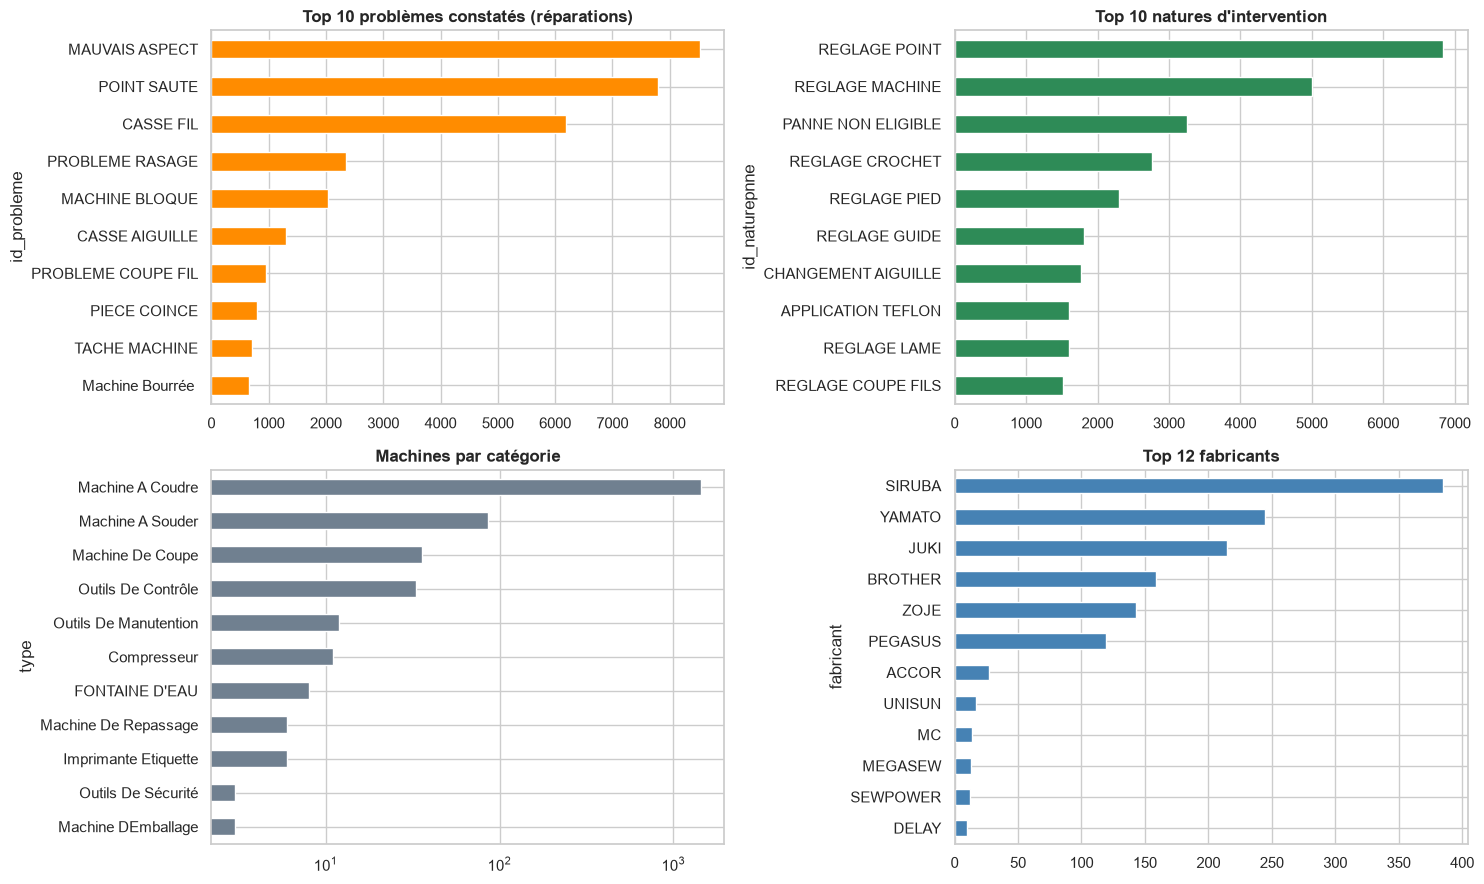

In [19]:
# Distributions catégorielles principales
nat_lbl  = raw['nature'].set_index('id_naturepanne').lib_naturepanne
prob_lbl = raw['probleme'].set_index('id_naturepanne').lib_naturepanne
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
r0.id_probleme.map(prob_lbl).value_counts().head(10).sort_values().plot.barh(ax=axes[0, 0], color='darkorange')
axes[0, 0].set_title('Top 10 problèmes constatés (réparations)')
r0.id_naturepnne.map(nat_lbl).value_counts().head(10).sort_values().plot.barh(ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('Top 10 natures d\'intervention')
raw['machine'].type.value_counts().sort_values().plot.barh(ax=axes[1, 0], color='slategray')
axes[1, 0].set_title('Machines par catégorie'); axes[1, 0].set_xscale('log')
raw['machine'].fabricant.value_counts().head(12).sort_values().plot.barh(ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title('Top 12 fabricants')
plt.tight_layout(); plt.show()

### 1.7 Variables quasiment constantes

In [20]:
qc = []
for t in ['machine', 'reparation', 'appel', 'entretien', 'preventif', 'historique', 'action', 'endroit']:
    df = raw[t]
    for c in df.columns:
        nn = df[c].notna().sum()
        if nn == 0:
            qc.append({'table': t, 'colonne': c, 'situation': '100 % vide', 'valeur dominante': '—', 'part_%': 100.0})
            continue
        vc = df[c].value_counts(normalize=True)
        share_nonnull = vc.iloc[0] * 100
        if share_nonnull >= 98 or df[c].isna().mean() >= 0.995:
            qc.append({'table': t, 'colonne': c,
                       'situation': 'quasi vide (>99,5 % NA)' if df[c].isna().mean() >= 0.995 else 'quasi constante',
                       'valeur dominante': str(vc.index[0])[:25], 'part_%': round(share_nonnull, 1)})
quasi_constantes = pd.DataFrame(qc)
print(len(quasi_constantes), 'colonnes vides ou (quasi) constantes')
quasi_constantes

43 colonnes vides ou (quasi) constantes


,table,colonne,situation,valeur dominante,part_%
0,machine,num_tete,100 % vide,—,100.0
1,machine,heuresactuelles,100 % vide,—,100.0
2,machine,cout_entretien,quasi constante,0.0,99.2
3,machine,vendu,quasi constante,f,100.0
4,machine,date_vente,100 % vide,—,100.0
5,machine,numero_soumission,100 % vide,—,100.0
6,machine,date_soumission,100 % vide,—,100.0
7,machine,date_fin_soumission,100 % vide,—,100.0
8,machine,site_designation,100 % vide,—,100.0
9,machine,site_id,100 % vide,—,100.0


### 1.8 Redondances entre variables et entre fichiers

In [21]:
m0, e0, h0, mv0, cl0, cat0 = raw['machine'], raw['entretien'], raw['historique'], raw['mouvement'], raw['classe'], raw['categorie']
mc  = m0.merge(cl0, left_on='id_class_machine', right_on='id_classe_machine', how='left')
mk  = m0.merge(cat0, left_on='id_categ_machine', right_on='id_categorie', how='left')
ra  = raw['appel'].merge(r0[['id_reparation', 'datearretchaine', 'id_probleme']], on='id_reparation')
hs, ms = h0.sort_values('id_historique_endroit').reset_index(drop=True), mv0.sort_values('id').reset_index(drop=True)

def eq(a, b):
    k = a.notna() & b.notna()
    return round((a[k] == b[k]).mean() * 100, 1)

red = pd.DataFrame([
    ('reparation', 'daterep  vs  date(dateheurerep)', eq(to_dt(r0.daterep).dt.normalize(), t_rep.dt.normalize())),
    ('reparation', 'datearretchaine_withouthour  vs  date(datearretchaine)', eq(to_dt(r0.datearretchaine_withouthour), t_arret.dt.normalize())),
    ('reparation', 'duree_attente (82 % NA)  vs  dureeattente', eq(r0.duree_attente, r0.dureeattente)),
    ('reparation', 'nom_machine (réparation)  vs  nom_machine (machine)',
        eq(r0.nom_machine, r0.id_machine_instance.map(m0.set_index('id_machine_instance').nom_machine))),
    ('machine', 'type  vs  categorie.lib_categorie', eq(mk.type, mk.lib_categorie)),
    ('machine', 'fabricant  vs  classe.fabricant', eq(mc.fabricant_x, mc.fabricant_y)),
    ('machine', 'nom_machine  vs  classe.desigantion', eq(mc.nom_machine, mc.desigantion)),
    ('machine', 'date_declaration  vs  date_achat', eq(to_dt(m0.date_declaration), to_dt(m0.date_achat))),
    ('appel', 'appel.id_problemepanne  vs  reparation.id_probleme', eq(ra.id_problemepanne, ra.id_probleme)),
    ('appel', '|date_appel - datearretchaine| < 1 min',
        round(((to_dt(ra.date_appel) - to_dt(ra.datearretchaine)).abs() < pd.Timedelta(minutes=1)).mean() * 100, 1)),
    ('mouvement', 'mouvement.machine  vs  historique.id_machine_instance (même ordre)', eq(ms.machine, hs.id_machine_instance)),
    ('mouvement', 'mouvement.destination  vs  historique.id_endroit', eq(ms.destination, hs.id_endroit)),
], columns=['table', 'comparaison', 'concordance_%'])
red

,table,comparaison,concordance_%
0,reparation,daterep vs date(dateheurerep),100.0
1,reparation,datearretchaine_withouthour vs date(datearretchaine),98.8
2,reparation,duree_attente (82 % NA) vs dureeattente,84.7
3,reparation,nom_machine (réparation) vs nom_machine (machine),97.3
4,machine,type vs categorie.lib_categorie,100.0
5,machine,fabricant vs classe.fabricant,99.9
6,machine,nom_machine vs classe.desigantion,90.0
7,machine,date_declaration vs date_achat,91.7
8,appel,appel.id_problemepanne vs reparation.id_probleme,100.0
9,appel,|date_appel - datearretchaine| < 1 min,93.0


## Étape 2 — Évaluation de la qualité des données (audit)

In [22]:
r0, a0, e0, p0, h0, m0 = raw['reparation'], raw['appel'], raw['entretien'], raw['preventif'], raw['historique'], raw['machine']
achat = m0.set_index('id_machine_instance').date_achat.pipe(to_dt)
nR, nE, nM = len(r0), len(e0), len(m0)
d_attente_rep = (r0.dureeattente + r0.dureerep - r0.dureearret).abs()
gap_fin = (t_fin - t_arret)
ent_dup = e0.duplicated(['id_machine_instance', 'id_action', 'date_heure_debut'])
retard = (to_dt(e0.date_debut) - to_dt(e0.date_prevue)).dt.days

A = []
def add(table, probleme, nb, base, decision):
    A.append({'table': table, 'problème': probleme, 'nb': int(nb), '%': pct(nb, base), 'décision': decision})

# --- Colonnes vides / quasi vides
for t in ['machine', 'reparation', 'appel', 'entretien', 'preventif', 'historique']:
    vides = raw[t].columns[raw[t].isna().mean() >= 0.995]
    add(t, f'colonnes vides (>=99,5 % NA) : {", ".join(vides)}', len(vides), raw[t].shape[1], 'supprimer : aucune information')
add('machine', 'cout (93 % NA), remarque (98 % NA)', 2, m0.shape[1], 'supprimer : trop peu renseignées pour être fiables')
add('reparation', 'id_produit / id_sousfamille / id_client / designation_process (~89 % NA)', 4, r0.shape[1],
    'supprimer : champs d\'un autre module (production), non liés à la panne')
# --- Doublons
add('reparation', 'doublons exacts', r0.duplicated().sum(), nR, '—')
add('reparation', 'lignes partageant (machine, date d\'arrêt) avec une autre',
    r0.duplicated(['id_machine_instance', 'datearretchaine'], keep=False).sum(), nR,
    'CONSERVER : natures / fins différentes -> plusieurs interventions sur un même arrêt (drapeau)')
add('entretien', 'doublons logiques (machine, action, même date-heure)', ent_dup.sum(), nE, 'supprimer : double saisie')
add('historique', 'doublons logiques (machine, date, emplacement)',
    h0.duplicated(['id_machine_instance', 'date_lecture', 'id_endroit']).sum(), len(h0), 'supprimer : lecture répétée')
# --- Durées
for c in ['dureearret', 'dureerep', 'dureeattente']:
    add('reparation', f'{c} négative', (r0[c] < 0).sum(), nR, 'mettre à NaN : durée impossible')
add('reparation', 'dureearret manquante', r0.dureearret.isna().sum(), nR, 'recalculer = attente + réparation si disponibles')
add('reparation', 'dureearret > 480 min (> 1 poste de travail)', (r0.dureearret > 480).sum(), nR,
    'conserver + drapeau : arrêts longs plausibles (pièce à commander)')
add('reparation', '|attente + réparation - arrêt| > 2 min', (d_attente_rep > 2).sum(), nR,
    'conserver : écarts dus à des saisies a posteriori ; dureearret = mesure de référence')
# --- Dates
add('reparation', 'datefin < datearretchaine (fin avant le début)', (gap_fin < pd.Timedelta(0)).sum(), nR, 'drapeau datefin_incoherente')
add('reparation', 'datefin > datearretchaine + 1 jour (clôture tardive)', (gap_fin > pd.Timedelta(days=1)).sum(), nR,
    'drapeau : datefin = date de clôture administrative, pas fin réelle')
add('reparation', 'réparation datée avant l\'achat de la machine',
    (t_arret < r0.id_machine_instance.map(achat)).sum(), nR, 'conserver (date d\'achat probablement erronée)')
add('reparation', 'réparation non clôturée (cloture = f)', (r0.cloture == 'f').sum(), nR,
    'conserver + variable binaire (les durées existent)')
add('entretien', 'date_debut postérieure à l\'extraction (planification future)', (to_dt(e0.date_debut) >= FIN_OBS).sum(), nE,
    'supprimer : non observé à la date d\'extraction')
add('entretien', 'entretien daté avant l\'achat de la machine',
    (to_dt(e0.date_debut) < e0.id_machine_instance.map(achat)).sum(), nE, 'conserver : l\'entretien a eu lieu, date d\'achat douteuse')
add('entretien', '|date_debut - date_prevue| > 365 j', (retard.abs() > 365).sum(), nE,
    'retard mis à NaN : planification incohérente')
add('machine', 'date_declaration < date_achat', (to_dt(m0.date_declaration) < to_dt(m0.date_achat)).sum(), nM,
    'sans impact : date_declaration non retenue')
add('machine', 'coûts cumulés négatifs (cout_total / cout_reparation)', ((m0.cout_total < 0) | (m0.cout_reparation < 0)).sum(), nM,
    'supprimer les coûts (incohérents + fuite de données)')
# --- Catégories incohérentes
add('reparation', 'categorie_reparation : casse incohérente (« PRODUCTION » vs « Production ») + modalités rares',
    r0.categorie_reparation.isin(['PRODUCTION', '2ème ETAGE', 'Dépôt KHALED', 'REFECTOIRE']).sum(), nR,
    'harmoniser la casse + regrouper les modalités rares en « Autre »')
add('machine', 'fabricant : variantes de casse / espaces', m0.fabricant.nunique() - norm_txt(m0.fabricant).nunique(), m0.fabricant.nunique(),
    'normaliser (majuscules, espaces)')
add('machine', 'nom_machine : variantes de casse / espaces', m0.nom_machine.nunique() - norm_txt(m0.nom_machine).nunique(), m0.nom_machine.nunique(),
    'normaliser (majuscules, espaces)')
add('endroit', 'nature : « Production » / « PRODUCTION » / « Hors Production  »', 3, raw['endroit'].nature.nunique(), 'normaliser')
add('probleme', 'libellé « Problème au niveau de purgeur d\'air » répété sous 3 identifiants', 3, len(raw['probleme']),
    'conserver les ids, harmoniser le libellé')
# --- Identifiants sans correspondance
add('toutes', 'clés étrangères orphelines', 0, 1, 'aucune action : intégrité 100 %')
add('appel', 'appel sans réparation associée', a0.id_reparation.isna().sum(), len(a0), 'conserver dans la table appel ; hors du dataset réparation')
add('machine', 'machines sans aucune réparation', (~m0.id_machine_instance.isin(r0.id_machine_instance)).sum(), nM,
    'conserver : machines « fiables » ou inactives (nb_rep = 0 est une information)')
# --- Valeurs manquantes catégorielles
add('machine', 'moteur manquant', m0.moteur.isna().sum(), nM, 'modalité « INCONNU » : l\'absence peut être informative')
add('reparation', 'nature / problème manquants', r0.id_naturepnne.isna().sum(), nR, 'modalité « INCONNU »')
audit = pd.DataFrame(A)
audit

,table,problème,nb,%,décision
0,machine,"colonnes vides (>=99,5 % NA) : num_tete, heuresactuelles, date_ven...",8,19.05,supprimer : aucune information
1,reparation,"colonnes vides (>=99,5 % NA) : id_process, origine, dateheure_vali...",7,16.67,supprimer : aucune information
2,appel,"colonnes vides (>=99,5 % NA) : date_fin_rep, reference, id_naturep...",4,28.57,supprimer : aucune information
3,entretien,"colonnes vides (>=99,5 % NA) : heuresactuelles, moisactuels, id_pe...",4,22.22,supprimer : aucune information
4,preventif,"colonnes vides (>=99,5 % NA) : frequence_autre, dernier_entretien_...",6,37.50,supprimer : aucune information
5,historique,"colonnes vides (>=99,5 % NA) : nom_machine, site_machine",2,28.57,supprimer : aucune information
6,machine,"cout (93 % NA), remarque (98 % NA)",2,4.76,supprimer : trop peu renseignées pour être fiables
7,reparation,id_produit / id_sousfamille / id_client / designation_process (~89...,4,9.52,"supprimer : champs d'un autre module (production), non liés à la p..."
8,reparation,doublons exacts,0,0.00,—
9,reparation,"lignes partageant (machine, date d'arrêt) avec une autre",1026,3.13,CONSERVER : natures / fins différentes -> plusieurs interventions ...


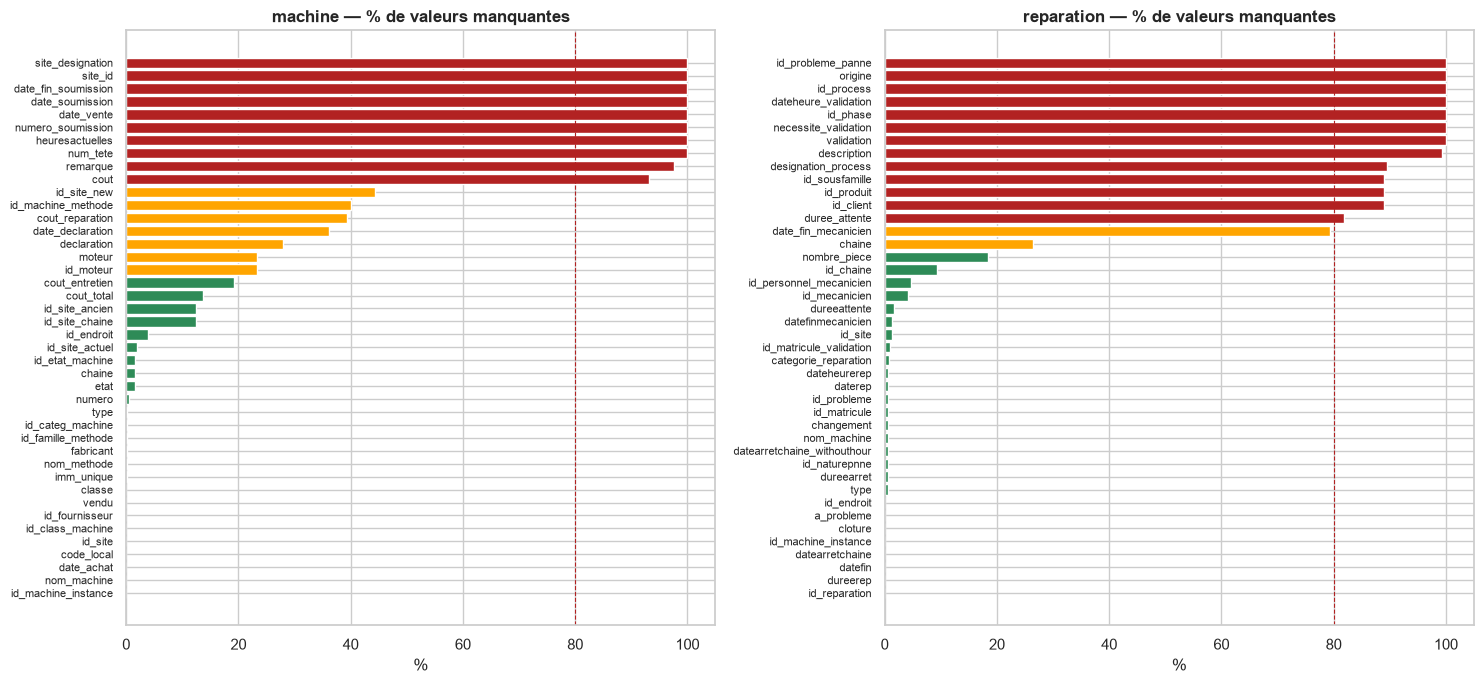

In [23]:
# Visualisation : taux de valeurs manquantes des deux tables les plus larges
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, t in zip(axes, ['machine', 'reparation']):
    na = (raw[t].isna().mean() * 100).sort_values()
    colors = ['firebrick' if v >= 80 else 'orange' if v >= 20 else 'seagreen' for v in na]
    ax.barh(na.index, na.values, color=colors)
    ax.axvline(80, ls='--', color='firebrick', lw=0.8)
    ax.set_title(f'{t} — % de valeurs manquantes'); ax.set_xlabel('%'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

## Étape 3 — Nettoyage et préparation

In [24]:
LOG = []
def log(table, operation, detail, justification):
    LOG.append({'table': table, 'opération': operation, 'détail': detail, 'justification': justification})

def drop_cols(df, cols, table, justification):
    cols = [c for c in cols if c in df.columns]
    log(table, 'suppression colonnes', ', '.join(cols), justification)
    return df.drop(columns=cols)

BOOL = {'t': 1, 'f': 0}

### 3.1 Référentiels (catégories, classes, natures, problèmes, actions, emplacements)

In [25]:
categorie = raw['categorie'].rename(columns={'lib_categorie': 'categorie_machine'}).copy()
categorie['categorie_machine'] = norm_txt(categorie.categorie_machine)

classe = raw['classe'].rename(columns={'desigantion': 'designation_classe', 'fabricant': 'fabricant_classe', 'ref': 'ref_classe'})
classe = drop_cols(classe, ['description'], 'classe', '95 % manquant, texte libre')
classe['designation_classe'] = norm_txt(classe.designation_classe)

# La table "probleme" réutilise les noms id_naturepanne/lib_naturepanne : on la renomme pour éviter toute confusion
nature = raw['nature'].rename(columns={'id_naturepanne': 'id_nature', 'lib_naturepanne': 'lib_nature', 'id_categorie': 'id_categorie_nature'})
nature['lib_nature'] = norm_txt(nature.lib_nature)
probleme = raw['probleme'].rename(columns={'id_naturepanne': 'id_probleme', 'lib_naturepanne': 'lib_probleme', 'id_categorie': 'id_categorie_probleme'})
probleme['lib_probleme'] = norm_txt(probleme.lib_probleme)
log('probleme', 'renommage', 'id_naturepanne->id_probleme, lib_naturepanne->lib_probleme', 'le contenu représente des problèmes, pas des natures')

# Actions : famille d'action = préfixe du libellé (M.C = machine à coudre, P.T = presse thermique, MG, C.A ...)
action = raw['action'][['id_action', 'nom_action']].copy()
action['famille_action'] = np.where(action.nom_action.str.contains(':'),
                                    action.nom_action.str.split(':').str[0].str.strip().str.upper(), 'AUTRE')
log('action', 'feature catégorielle', 'famille_action = préfixe avant « : »', 'regroupe 62 libellés longs en familles lisibles')

endroit = raw['endroit'][['id_endroit', 'nom_endroit', 'id_site', 'nature', 'depannage', 'preventifexclu']].copy()
endroit['nature'] = norm_txt(endroit.nature)
endroit['type_endroit'] = endroit.nature.where(endroit.nature.isin(['PRODUCTION', 'PARC', 'COUPE', 'DEVELOPPEMENT', 'HORS PRODUCTION']), 'AUTRE').fillna('AUTRE')
endroit[['depannage', 'preventifexclu']] = endroit[['depannage', 'preventifexclu']].replace(BOOL)
log('endroit', 'harmonisation', 'nature normalisée -> type_endroit (6 modalités)', 'casse incohérente + modalités rares')
display(action.famille_action.value_counts().head(10).to_frame().T, endroit.type_endroit.value_counts().to_frame().T)

famille_action,AUTRE,M.C,C.A,C.M,MG,TR,ECH.M.M,DÉCOUPOIR,F D'EAU,SR
count,25,3,3,3,3,2,2,2,2,2


type_endroit,PRODUCTION,PARC,HORS PRODUCTION,AUTRE,COUPE,DEVELOPPEMENT
count,37,19,5,5,1,1


### 3.2 Machines

In [26]:
m = raw['machine'].copy()
m = drop_cols(m, m.columns[m.isna().all()].tolist(), 'machine', 'colonnes 100 % vides')
m = drop_cols(m, ['vendu'], 'machine', 'constante (f partout)')
m = drop_cols(m, ['cout_total', 'cout_reparation', 'cout_entretien'], 'machine',
              'cumuls ERP calculés avec des événements futurs (DATA LEAKAGE) + valeurs négatives + 55 % de zéros')
m = drop_cols(m, ['cout', 'remarque'], 'machine', '93 % / 98 % manquants')
m = drop_cols(m, ['type', 'classe', 'chaine', 'id_moteur', 'id_etat_machine', 'nom_machine'], 'machine',
              'redondantes : libellé repris via jointure (catégorie, classe, emplacement) ou doublon d\'un autre champ')
m = drop_cols(m, ['date_declaration', 'declaration', 'imm_unique', 'numero', 'id_machine_methode',
                  'id_site_new', 'id_site_actuel', 'id_site_chaine', 'id_site_ancien'], 'machine',
              'identifiants techniques / variantes de site ambiguës ; date_achat retenue comme date de référence')

m['date_achat'] = to_dt(m.date_achat)
m['fabricant']  = norm_txt(m.fabricant).fillna('INCONNU')
m['moteur']     = norm_txt(m.moteur).fillna('INCONNU')
m['etat']       = norm_txt(m.etat).fillna('INCONNU')
m['nom_methode'] = norm_txt(m.nom_methode).fillna('INCONNU')
log('machine', 'valeurs manquantes', 'fabricant/moteur/etat/nom_methode -> « INCONNU »', 'absence conservée comme information, sans imputation arbitraire')

# Décodage via référentiels (jointures N-1, contrôlées)
n0 = len(m)
m = m.merge(categorie, left_on='id_categ_machine', right_on='id_categorie', how='left', validate='m:1').drop(columns='id_categorie')
m = m.merge(classe[['id_classe_machine', 'designation_classe']], left_on='id_class_machine',
            right_on='id_classe_machine', how='left', validate='m:1').drop(columns='id_classe_machine')
assert len(m) == n0
m['categorie_machine'] = m.categorie_machine.fillna('INCONNUE')
m['annee_achat'] = m.date_achat.dt.year
machines = m
print(machines.shape); machines.head()

(1649, 16)


,id_machine_instance,code_local,date_achat,etat,id_fournisseur,id_site,id_class_machine,id_categ_machine,id_endroit,nom_methode,moteur,fabricant,id_famille_methode,categorie_machine,designation_classe,annee_achat
0,814,FD5616,2019-09-23,EN BON ETAT,20,1,302,35.0,11.0,FLAT,ECONOMIQUE,YAMATO,1.0,MACHINE A COUDRE,FLATLOCK,2019
1,1212299,220525007,2022-12-01,EN BON ETAT,2,5,1115180,35.0,799317.0,ZIGZAGUE,ECONOMIQUE,STONE,2.0,MACHINE A COUDRE,ZIGZAGUEUSE,2022
2,1237219,120K029560,2023-05-09,EN BON ETAT,16,4,925495,35.0,783329.0,S4F,ECONOMIQUE,SIRUBA,11.0,MACHINE A COUDRE,SURJETEUSE 4 FILS COUPE CHAINETTE,2023
3,1011,MBOCE62830,2019-07-20,EN BON ETAT,20,4,444,35.0,13.0,POSE BOUTON,NON ECONOMIQUE,JUKI,9.0,MACHINE A COUDRE,POSE BOUTON-PT CHAINETTE,2019
4,1245,YM57013,2021-07-06,EN BON ETAT,2,4,419,35.0,13.0,S3FPROG,ECONOMIQUE,YAMATO,13.0,MACHINE A COUDRE,SURJETEUSE POSE LAMINETTE,2021


### 3.3 Réparations

In [27]:
r = raw['reparation'].copy()
n_before = r.shape
r = drop_cols(r, r.columns[r.isna().mean() >= 0.995].tolist(), 'reparation', 'colonnes vides (>= 99,5 % NA)')
r = drop_cols(r, ['daterep', 'datearretchaine_withouthour', 'date_fin_mecanicien', 'duree_attente', 'nom_machine'],
              'reparation', 'redondantes (cf. 1.8)')
r = drop_cols(r, ['description', 'designation_process', 'id_produit', 'id_sousfamille', 'id_client'],
              'reparation', '> 89 % manquants, hors périmètre panne')
r = drop_cols(r, ['nombre_piece', 'type'], 'reparation', 'constante / quasi constante (> 99 %)')
r = drop_cols(r, ['id_chaine', 'chaine', 'id_site', 'id_matricule', 'id_matricule_validation', 'id_personnel_mecanicien'],
              'reparation', 'redondant avec id_endroit (ligne) / identifiants de personnel hors sujet')

r = r.rename(columns={'datearretchaine': 'date_arret', 'dateheurerep': 'date_prise_en_charge',
                      'datefinmecanicien': 'date_fin_intervention', 'datefin': 'date_cloture',
                      'dureearret': 'duree_arret_min', 'dureerep': 'duree_rep_min', 'dureeattente': 'duree_attente_min',
                      'id_naturepnne': 'id_nature', 'id_endroit': 'id_ligne'})
for c in ['date_arret', 'date_prise_en_charge', 'date_fin_intervention', 'date_cloture']:
    r[c] = to_dt(r[c])
for c in ['changement', 'a_probleme', 'cloture']:
    r[c] = r[c].map(BOOL)
log('reparation', 'conversion types', 'dates ISO 8601 ; t/f -> 1/0', 'types exploitables')

# Durées : valeurs impossibles -> NaN ; arrêt manquant reconstruit
for c in ['duree_arret_min', 'duree_rep_min', 'duree_attente_min']:
    k = (r[c] < 0).sum(); r.loc[r[c] < 0, c] = np.nan
    log('reparation', 'valeurs impossibles', f'{c} < 0 -> NaN ({k} lignes)', 'une durée ne peut être négative')
miss = r.duree_arret_min.isna() & r.duree_attente_min.notna() & r.duree_rep_min.notna()
r.loc[miss, 'duree_arret_min'] = r.loc[miss, 'duree_attente_min'] + r.loc[miss, 'duree_rep_min']
log('reparation', 'imputation déterministe', f'duree_arret = attente + réparation ({miss.sum()} lignes)', 'identité vérifiée en 1.6')

# Drapeaux de qualité (on conserve l'information au lieu de supprimer)
r['flag_arret_long'] = (r.duree_arret_min > 480).astype(int)
gap = r.date_cloture - r.date_arret
r['flag_date_cloture_incoherente'] = ((gap < pd.Timedelta(0)) | (gap > pd.Timedelta(days=1))).astype(int)
log('reparation', 'drapeaux', 'flag_arret_long (> 480 min), flag_date_cloture_incoherente', 'valeurs extrêmes conservées mais tracées')

# Harmonisation catégorielle
cat = r.categorie_reparation.str.strip().str.title()
r['categorie_reparation'] = cat.where(cat.isin(['Production', 'Developpement', 'Coupe', 'Parc']), 'Autre')
r.loc[raw['reparation'].categorie_reparation.isna(), 'categorie_reparation'] = 'Inconnue'
log('reparation', 'harmonisation', 'categorie_reparation : casse + modalités rares -> Autre / NA -> Inconnue', '9 modalités -> 6')

# Plusieurs interventions pour un même arrêt (même machine, même horodatage d'arrêt) :
# l'examen montre des natures, des fins et des durées DIFFÉRENTES -> ce ne sont pas des doublons, on les conserve et on les trace
r['nb_interventions_arret'] = r.groupby(['id_machine_instance', 'date_arret']).id_reparation.transform('size')
r['intervention_multiple'] = (r.nb_interventions_arret > 1).astype(int)
log('reparation', 'pseudo-doublons conservés',
    f'{r.intervention_multiple.sum()} lignes partagent (machine, date_arret) avec une autre',
    'interventions successives sur un même arrêt (natures/fins différentes) : pas une double saisie')

reparations = r.sort_values(['id_machine_instance', 'date_arret']).reset_index(drop=True)
print(n_before, '->', reparations.shape)
reparations.head()

(32772, 42) -> (32772, 21)


,id_reparation,date_prise_en_charge,duree_rep_min,date_arret,duree_arret_min,date_cloture,id_nature,id_ligne,id_machine_instance,changement,id_probleme,id_mecanicien,a_probleme,cloture,date_fin_intervention,duree_attente_min,categorie_reparation,flag_arret_long,flag_date_cloture_incoherente,nb_interventions_arret,intervention_multiple
0,781137,2021-11-16 14:12:53.440,7.0,2021-11-16 14:12:07.581,7.0,2021-11-16 14:19:09.029,780535.0,13.0,215,0.0,780530.0,NaN,0,1,2021-11-16 14:19:09.029,0.0,Parc,0,0,1,0
1,1053827,2022-11-11 11:12:00.198,2.0,2022-11-11 11:09:00.198,5.0,2022-11-11 11:14:00.198,800065.0,15.0,222,0.0,946752.0,878940.0,0,1,2022-11-11 11:12:00.198,3.0,Coupe,0,0,2,1
2,1053831,2022-11-11 11:13:08.153,76.0,2022-11-11 11:09:00.198,80.0,2022-11-11 12:29:43.425,800039.0,15.0,222,0.0,946752.0,NaN,0,0,2022-11-11 12:29:43.425,NaN,Coupe,0,0,2,1
3,1055972,2022-11-15 07:28:30.888,3.0,2022-11-15 07:22:33.568,6.0,2022-11-15 08:15:35.667,952452.0,15.0,222,0.0,946752.0,878940.0,0,1,2022-11-15 07:47:51.211,3.0,Coupe,0,0,1,0
4,1063276,2022-11-24 09:23:43.774,40.0,2022-11-24 09:23:09.428,294.0,2022-11-24 14:17:24.719,800039.0,15.0,222,0.0,946752.0,878940.0,0,1,2022-11-24 10:03:15.085,0.0,Coupe,0,0,1,0


### 3.4 Appels de panne

In [28]:
a = raw['appel'].copy()
a = drop_cols(a, a.columns[a.isna().all()].tolist() + ['cloture'], 'appel', 'colonnes vides + cloture constante (t)')
a = drop_cols(a, ['id_matricule', 'id_endroit'], 'appel', 'personnel hors sujet / emplacement déjà présent dans réparation')
a['date_appel'] = to_dt(a.date_appel); a['date_consult'] = to_dt(a.date_consult)
a['changement'] = a.changement.map(BOOL)
a['delai_consultation_min'] = (a.date_consult - a.date_appel).dt.total_seconds() / 60
log('appel', 'feature', 'delai_consultation_min = date_consult - date_appel', 'réactivité de prise en charge du signalement')
appels = a
print(appels.shape); appels.delai_consultation_min.describe(percentiles=[.5, .9, .99]).round(1)

(32331, 8)


count      31841.0
mean         213.1
std         7800.4
min            0.0
50%            5.3
90%          115.6
99%         3771.1
max      1380975.0
Name: delai_consultation_min, dtype: float64

### 3.5 Entretiens

In [29]:
e = raw['entretien'].copy()
n_before = e.shape
e = drop_cols(e, ['heuresactuelles', 'moisactuels', 'id_personnel_mecanicien_planning', 'id_mecanicien_planning'],
              'entretien', 'vides ou 5 valeurs sur 65 173')
e = drop_cols(e, ['faite'], 'entretien', 'quasi constante (1 seule valeur t) : indicateur non utilisé par l\'ERP')
e = drop_cols(e, ['chaine', 'id_personnel_mecanicien', 'id_site'], 'entretien', 'redondant avec id_endroit / personnel hors sujet')

e['date_heure_debut'] = to_dt(e.date_heure_debut); e['date_debut'] = to_dt(e.date_debut); e['date_prevue'] = to_dt(e.date_prevue)

# 1) Observations hors période : planifications postérieures à l'extraction
fut = e.date_debut >= FIN_OBS
e = e[~fut]
log('entretien', 'hors période', f'{fut.sum()} entretiens après le {DATE_EXTRACTION.date()} supprimés', 'planification, non observée')
# 2) Doublons logiques
dup = e.duplicated(['id_machine_instance', 'id_action', 'date_heure_debut'])
e = e[~dup]
log('entretien', 'doublons logiques', f'{dup.sum()} lignes (machine, action, date-heure) supprimées', 'double saisie')
# 3) Retard par rapport à la planification
e['retard_jours'] = (e.date_debut - e.date_prevue).dt.days
inc = e.retard_jours.abs() > 365
e.loc[inc, 'retard_jours'] = np.nan
log('entretien', 'valeurs incohérentes', f'retard |>365 j| -> NaN ({inc.sum()} lignes)', 'date prévue manifestement erronée')
e = e.rename(columns={'duree': 'duree_ent', 'dureearret': 'duree_arret_ent'})
e = e.merge(action[['id_action', 'famille_action']], on='id_action', how='left', validate='m:1')

entretiens = e.sort_values(['id_machine_instance', 'date_debut']).reset_index(drop=True)
print(n_before, '->', entretiens.shape)
entretiens.head()

(65173, 18) -> (63899, 12)


,id_entretien,date_heure_debut,date_debut,duree_ent,id_action,id_machine_instance,duree_arret_ent,date_prevue,id_mecanicien,id_endroit,retard_jours,famille_action
0,1018801,2022-08-15 12:00:00,2022-08-15,66,1018790,222,0.0,NaT,878940.0,NaN,NaN,C.A
1,1018803,2022-08-15 12:00:00,2022-08-15,66,1018794,222,0.0,NaT,878940.0,NaN,NaN,C.A
2,1018804,2022-08-15 12:00:00,2022-08-15,66,948127,222,0.0,NaT,878940.0,NaN,NaN,C.A
3,1018805,2022-09-26 12:00:00,2022-09-26,5,1018790,222,0.0,2022-08-22,878940.0,NaN,35.0,C.A
4,1018807,2022-09-26 12:00:00,2022-09-26,5,1018794,222,0.0,2022-09-12,878940.0,NaN,14.0,C.A


### 3.6 Préventif et historique des emplacements

In [30]:
p = raw['preventif'].copy()
p = drop_cols(p, p.columns[p.isna().all()].tolist() + ['description', 'faite_affectation'], 'preventif',
              'vides / > 95 % manquants')
for c in ['dernier_entretien_jour', 'prochain_entretien_jour', 'avant_dernier', 'date_affectation']:
    p[c] = to_dt(p[c])
p['faite'] = p.faite.map(BOOL)
preventif = p

h = raw['historique'].copy()
h = drop_cols(h, ['nom_machine', 'site_machine', 'actif'], 'historique', 'vides / constante')
h['date_lecture'] = to_dt(h.date_lecture)
dup = h.duplicated(['id_machine_instance', 'date_lecture', 'id_endroit'])
h = h[~dup]
log('historique', 'doublons logiques', f'{dup.sum()} lectures identiques supprimées', 'lecture répétée sans changement')
historique = h.sort_values(['id_machine_instance', 'date_lecture', 'id_historique_endroit']).reset_index(drop=True)
log('mouvement', 'table écartée', 'gm_mouvementmachine non utilisée', 'copie de historique, sans date (cf. 1.8)')
print('preventif', preventif.shape, '| historique', historique.shape)

preventif (4109, 9) | historique (14654, 4)


In [31]:
journal = pd.DataFrame(LOG)
journal

,table,opération,détail,justification
0,classe,suppression colonnes,description,"95 % manquant, texte libre"
1,probleme,renommage,"id_naturepanne->id_probleme, lib_naturepanne->lib_probleme","le contenu représente des problèmes, pas des natures"
2,action,feature catégorielle,famille_action = préfixe avant « : »,regroupe 62 libellés longs en familles lisibles
3,endroit,harmonisation,nature normalisée -> type_endroit (6 modalités),casse incohérente + modalités rares
4,machine,suppression colonnes,"num_tete, heuresactuelles, date_vente, numero_soumission, date_sou...",colonnes 100 % vides
5,machine,suppression colonnes,vendu,constante (f partout)
6,machine,suppression colonnes,"cout_total, cout_reparation, cout_entretien",cumuls ERP calculés avec des événements futurs (DATA LEAKAGE) + va...
7,machine,suppression colonnes,"cout, remarque",93 % / 98 % manquants
8,machine,suppression colonnes,"type, classe, chaine, id_moteur, id_etat_machine, nom_machine","redondantes : libellé repris via jointure (catégorie, classe, empl..."
9,machine,suppression colonnes,"date_declaration, declaration, imm_unique, numero, id_machine_meth...",identifiants techniques / variantes de site ambiguës ; date_achat ...


## Étape 4 — Intégration des données (jointures contrôlées)

In [32]:
def merge_controle(left, right, nom, validate='m:1', **kw):
    n0 = len(left)
    out = left.merge(right, how='left', validate=validate, indicator=True, **kw)
    taux = (out['_merge'] == 'both').mean() * 100
    out = out.drop(columns='_merge')
    print(f'{nom:<42} {n0:>7} -> {len(out):>7} lignes | correspondance {taux:6.2f} % | {validate}')
    assert len(out) == n0, 'La jointure a dupliqué des lignes !'
    return out

### 4.1 Dataset « réparations enrichies » : 1 ligne = 1 réparation

In [33]:
MACHINE_COLS = ['id_machine_instance', 'categorie_machine', 'designation_classe', 'fabricant', 'nom_methode',
                'moteur', 'date_achat', 'id_site']
APPEL_COLS = ['id_reparation', 'id_appel', 'date_appel', 'delai_consultation_min']

rep = reparations.copy()
rep = merge_controle(rep, nature[['id_nature', 'lib_nature']], 'réparation × nature (N-1)', on='id_nature')
rep = merge_controle(rep, probleme[['id_probleme', 'lib_probleme']], 'réparation × problème (N-1)', on='id_probleme')
rep = merge_controle(rep, endroit[['id_endroit', 'nom_endroit']].rename(columns={'id_endroit': 'id_ligne', 'nom_endroit': 'ligne'}),
                     'réparation × ligne / emplacement (N-1)', on='id_ligne')
rep = merge_controle(rep, machines[MACHINE_COLS], 'réparation × machine (N-1)', on='id_machine_instance')
rep = merge_controle(rep, appels.loc[appels.id_reparation.notna(), APPEL_COLS], 'réparation × appel (1-1)',
                     on='id_reparation', validate='1:1')

rep['lib_nature']   = rep.lib_nature.fillna('INCONNU')
rep['lib_probleme'] = rep.lib_probleme.fillna('INCONNU')
rep['age_machine_jours'] = (rep.date_arret - rep.date_achat).dt.days
rep['flag_avant_achat'] = (rep.age_machine_jours < 0).astype(int)
rep['heure_arret'] = rep.date_arret.dt.hour
rep['jour_semaine'] = rep.date_arret.dt.dayofweek
rep['mois'] = rep.date_arret.dt.month
reparations_enrichies = rep
print(reparations_enrichies.shape)
reparations_enrichies.head(3)

réparation × nature (N-1)                    32772 ->   32772 lignes | correspondance  99.44 % | m:1
réparation × problème (N-1)                  32772 ->   32772 lignes | correspondance  99.40 % | m:1
réparation × ligne / emplacement (N-1)       32772 ->   32772 lignes | correspondance  99.99 % | m:1
réparation × machine (N-1)                   32772 ->   32772 lignes | correspondance 100.00 % | m:1


réparation × appel (1-1)                     32772 ->   32772 lignes | correspondance  97.36 % | 1:1
(32772, 39)


,id_reparation,date_prise_en_charge,duree_rep_min,date_arret,duree_arret_min,date_cloture,id_nature,id_ligne,id_machine_instance,changement,id_probleme,id_mecanicien,a_probleme,cloture,date_fin_intervention,duree_attente_min,categorie_reparation,flag_arret_long,flag_date_cloture_incoherente,nb_interventions_arret,intervention_multiple,lib_nature,lib_probleme,ligne,categorie_machine,designation_classe,fabricant,nom_methode,moteur,date_achat,id_site,id_appel,date_appel,delai_consultation_min,age_machine_jours,flag_avant_achat,heure_arret,jour_semaine,mois
0,781137,2021-11-16 14:12:53.440,7.0,2021-11-16 14:12:07.581,7.0,2021-11-16 14:19:09.029,780535.0,13.0,215,0.0,780530.0,NaN,0,1,2021-11-16 14:19:09.029,0.0,Parc,0,0,1,0,REGLAGE CROCHET,MACHINE BLOQUE,Atelier ENFAVET PLUS,IMPRIMANTE ETIQUETTE,IMPRIMANTE VIGNETTE,ETIC EUROPE,ND,INCONNU,2018-05-07,2,781136.0,2021-11-16 14:12:07.581,0.764317,1289,0,14,1,11
1,1053827,2022-11-11 11:12:00.198,2.0,2022-11-11 11:09:00.198,5.0,2022-11-11 11:14:00.198,800065.0,15.0,222,0.0,946752.0,878940.0,0,1,2022-11-11 11:12:00.198,3.0,Coupe,0,0,2,1,PANNE ELECTRIQUE,AC.COUPE NON CONFORME,Coupe ENFAVET INTER,MACHINE DE COUPE,COUPE AUTOMATIQUE,GERBER TECHNOLOGY,ND,INCONNU,2011-04-25,1,NaN,NaT,NaN,4218,0,11,4,11
2,1053831,2022-11-11 11:13:08.153,76.0,2022-11-11 11:09:00.198,80.0,2022-11-11 12:29:43.425,800039.0,15.0,222,0.0,946752.0,NaN,0,0,2022-11-11 12:29:43.425,NaN,Coupe,0,0,2,1,REGLAGE LAME,AC.COUPE NON CONFORME,Coupe ENFAVET INTER,MACHINE DE COUPE,COUPE AUTOMATIQUE,GERBER TECHNOLOGY,ND,INCONNU,2011-04-25,1,1053774.0,2022-11-11 11:09:00.198,4.132583,4218,0,11,4,11


### 4.2 Pourquoi on ne joint pas directement les tables d'événements entre elles

In [34]:
naif = reparations[['id_reparation', 'id_machine_instance']].merge(
    entretiens[['id_entretien', 'id_machine_instance']], on='id_machine_instance')
print(f'Réparations : {len(reparations):,} | Entretiens : {len(entretiens):,} | '
      f'Jointure naïve : {len(naif):,} lignes (x{len(naif)/len(reparations):.0f})')
print('Une même réparation apparaît jusqu\'à', naif.id_reparation.value_counts().max(), 'fois.')

Réparations : 32,772 | Entretiens : 63,899 | Jointure naïve : 1,719,178 lignes (x52)


Une même réparation apparaît jusqu'à 685 fois.


## Étape 5 — Feature Engineering

### 5.1 Unité d'analyse et règle temporelle

### 5.2 Regroupement des catégories rares

In [35]:
def regrouper(s, top=None, min_n=None, autre='AUTRE'):
    vc = s.value_counts()
    keep = vc.head(top).index if top else vc[vc >= min_n].index
    return s.where(s.isin(keep), autre)

machines['fabricant_grp']   = regrouper(machines.fabricant, top=8)
machines['categorie_grp']   = regrouper(machines.categorie_machine, min_n=30)
machines['designation_grp'] = regrouper(machines.designation_classe.fillna('INCONNU'), top=12)
machines['methode_grp']     = regrouper(machines.nom_methode, top=10)
SOURCE_GRP = {'fabricant_grp': 'fabricant', 'categorie_grp': 'categorie_machine',
              'designation_grp': 'designation_classe', 'methode_grp': 'nom_methode'}
for grp, src in SOURCE_GRP.items():
    print(f'{src:<20} {machines[src].nunique():>4} modalités -> {grp:<16} {machines[grp].nunique():>3} modalités')
    log('machine', 'regroupement', f'{src} -> {grp}', 'modalités rares regroupées en AUTRE')

fabricant             115 modalités -> fabricant_grp      9 modalités
categorie_machine      12 modalités -> categorie_grp      5 modalités
designation_classe    104 modalités -> designation_grp   13 modalités
nom_methode            32 modalités -> methode_grp       11 modalités


### 5.3 Construction des features à une date T

In [36]:
FENETRES = [30, 90, 180]
DEBUT_HISTO = reparations.date_arret.min().normalize()     # début des données événementielles

def build_machine_snapshot(T, rep=None, ent=None, hist=None):
    # Construit 1 ligne par machine (achetée avant T) avec des features issues UNIQUEMENT d'événements < T
    T = pd.Timestamp(T)
    rep  = reparations if rep  is None else rep
    ent  = entretiens  if ent  is None else ent
    hist = historique  if hist is None else hist

    # --- Base statique (référentiel)
    X = machines.loc[machines.date_achat < T, ['id_machine_instance', 'categorie_grp', 'fabricant_grp', 'designation_grp',
                                               'methode_grp', 'moteur', 'id_site', 'date_achat']].set_index('id_machine_instance')
    X['age_jours'] = (T - X.date_achat).dt.days
    X['exposition_jours'] = (T - X.date_achat.clip(lower=DEBUT_HISTO)).dt.days.clip(lower=1)

    # --- Réparations antérieures à T
    r = rep[rep.date_arret < T]
    g = r.groupby('id_machine_instance')
    X = X.join(pd.DataFrame({
        'nb_rep_total': g.size(),
        'nb_arrets_distincts': g.date_arret.nunique(),
        'duree_arret_moy': g.duree_arret_min.mean(),
        'duree_arret_totale': g.duree_arret_min.sum(),
        'duree_rep_moy': g.duree_rep_min.mean(),
        'duree_attente_moy': g.duree_attente_min.mean(),
        'nb_problemes_distincts': g.id_probleme.nunique(),
        'nb_natures_distinctes': g.id_nature.nunique(),
        'taux_rep_avec_changement': g.changement.mean(),
        'nb_arrets_longs': g.flag_arret_long.sum(),
        '_derniere_rep': g.date_arret.max()}))
    for w in FENETRES:
        X[f'nb_rep_{w}j'] = r[r.date_arret >= T - pd.Timedelta(days=w)].groupby('id_machine_instance').size()

    # --- Entretiens antérieurs à T
    e = ent[ent.date_debut < T]
    ge = e.groupby('id_machine_instance')
    X = X.join(pd.DataFrame({
        'nb_ent_total': ge.size(),
        'nb_actions_ent_distinctes': ge.id_action.nunique(),
        'retard_ent_moy_jours': ge.retard_jours.mean(),
        'duree_ent_totale': ge.duree_ent.sum(),
        '_dernier_ent': ge.date_debut.max()}))
    X['nb_ent_90j'] = e[e.date_debut >= T - pd.Timedelta(days=90)].groupby('id_machine_instance').size()

    # --- Mobilité (historique daté des emplacements) antérieure à T
    hh = hist[hist.date_lecture < T].sort_values(['id_machine_instance', 'date_lecture', 'id_historique_endroit'])
    gh = hh.groupby('id_machine_instance')
    hh = hh.assign(chg=hh.id_endroit.ne(gh.id_endroit.shift()) & gh.cumcount().gt(0))
    X = X.join(pd.DataFrame({'nb_changements_emplacement': hh.groupby('id_machine_instance').chg.sum(),
                             '_endroit_T': hh.groupby('id_machine_instance').id_endroit.last()}))
    X['type_endroit_T'] = X._endroit_T.map(endroit.set_index('id_endroit').type_endroit).fillna('INCONNU')

    # --- Valeurs pour les machines sans événement : 0 = « aucun événement », pas une donnée manquante
    zero_cols = ['nb_rep_total', 'nb_arrets_distincts', 'duree_arret_totale', 'nb_problemes_distincts', 'nb_natures_distinctes', 'nb_arrets_longs',
                 'nb_ent_total', 'nb_actions_ent_distinctes', 'duree_ent_totale', 'nb_ent_90j', 'nb_changements_emplacement'] \
                + [f'nb_rep_{w}j' for w in FENETRES]
    X[zero_cols] = X[zero_cols].fillna(0).astype(int)
    X['jamais_reparee']  = (X.nb_rep_total == 0).astype(int)
    X['jamais_entretenue'] = (X.nb_ent_total == 0).astype(int)
    for c in ['duree_arret_moy', 'duree_rep_moy', 'duree_attente_moy', 'taux_rep_avec_changement', 'retard_ent_moy_jours']:
        X[c] = X[c].fillna(0)
    # Temps écoulés : censurés à la durée d'exposition si aucun événement
    X['jours_depuis_derniere_rep'] = (T - X._derniere_rep).dt.days.fillna(X.exposition_jours)
    X['jours_depuis_dernier_ent']  = (T - X._dernier_ent).dt.days.fillna(X.exposition_jours)

    # --- Features dérivées (ratios, tendances)
    X['freq_rep_mensuelle'] = X.nb_rep_total / (X.exposition_jours / 30.44)
    X['tendance_rep'] = (X.nb_rep_30j + 1) / (X.nb_rep_180j / 6 + 1)   # >1 : accélération récente des pannes
    X['ratio_prev_corr'] = X.nb_ent_total / (X.nb_rep_total + 1)

    # --- Informations instantanées de l'ERP : valides seulement à la date d'extraction
    if T >= DATE_EXTRACTION:
        X['etat_actuel'] = machines.set_index('id_machine_instance').etat
        pv = preventif.groupby('id_machine_instance')
        X['freq_prev_min_jours'] = pv.frequence_jour.min()
        X['nb_actions_prev_planifiees'] = pv.size()
        X['nb_actions_prev_planifiees'] = X.nb_actions_prev_planifiees.fillna(0).astype(int)
        X['freq_prev_min_jours'] = X.freq_prev_min_jours.fillna(-1)   # -1 = aucun préventif configuré

    X = X.drop(columns=[c for c in X.columns if c.startswith('_')] + ['date_achat'])
    X.insert(0, 'date_observation', T)
    return X.reset_index()

T_REF = FIN_OBS          # observation « au lendemain de l'extraction » : tout l'historique est disponible
snapshot = build_machine_snapshot(T_REF)
print(snapshot.shape)
snapshot.head()

(1649, 40)


,id_machine_instance,date_observation,categorie_grp,fabricant_grp,designation_grp,methode_grp,moteur,id_site,age_jours,exposition_jours,nb_rep_total,nb_arrets_distincts,duree_arret_moy,duree_arret_totale,duree_rep_moy,duree_attente_moy,nb_problemes_distincts,nb_natures_distinctes,taux_rep_avec_changement,nb_arrets_longs,nb_rep_30j,nb_rep_90j,nb_rep_180j,nb_ent_total,nb_actions_ent_distinctes,retard_ent_moy_jours,duree_ent_totale,nb_ent_90j,nb_changements_emplacement,type_endroit_T,jamais_reparee,jamais_entretenue,jours_depuis_derniere_rep,jours_depuis_dernier_ent,freq_rep_mensuelle,tendance_rep,ratio_prev_corr,etat_actuel,freq_prev_min_jours,nb_actions_prev_planifiees
0,814,2026-03-06,MACHINE A COUDRE,YAMATO,FLATLOCK,FLAT,ECONOMIQUE,1,2356,1574,36,34,25.942857,908,12.027778,16.424242,6,9,0.114286,0,1,1,9,55,3,-1.211538,341,2,10,PARC,0,0,10.0,59.0,0.696213,0.800000,1.486486,EN BON ETAT,28.0,3
1,1212299,2026-03-06,MACHINE A COUDRE,AUTRE,AUTRE,AUTRE,ECONOMIQUE,5,1191,1191,45,45,19.318182,850,13.488889,4.522727,8,10,0.022727,0,1,3,17,0,0,0.000000,0,0,7,DEVELOPPEMENT,0,1,1.0,1191.0,1.150126,0.521739,0.000000,EN BON ETAT,28.0,3
2,1237219,2026-03-06,MACHINE A COUDRE,SIRUBA,SURJETEUSE 4 FILS COUPE CHAINETTE,S4F,ECONOMIQUE,4,1032,1032,30,28,12.500000,375,9.000000,3.344828,8,8,0.000000,0,0,2,6,0,0,0.000000,0,0,17,PRODUCTION,0,1,42.0,1032.0,0.884884,0.500000,0.000000,EN BON ETAT,-1.0,0
3,1011,2026-03-06,MACHINE A COUDRE,JUKI,AUTRE,AUTRE,NON ECONOMIQUE,4,2421,1574,16,15,10.812500,173,5.625000,4.866667,5,8,0.000000,0,1,1,1,60,3,-12.379310,273,2,16,PRODUCTION,0,0,21.0,23.0,0.309428,1.714286,3.529412,EN BON ETAT,28.0,3
4,1245,2026-03-06,MACHINE A COUDRE,YAMATO,SURJETEUSE POSE LAMINETTE,S3FPROG,ECONOMIQUE,4,1704,1574,19,19,17.000000,323,10.421053,5.631579,9,6,0.000000,0,0,1,2,57,3,0.000000,285,1,19,PARC,0,0,72.0,59.0,0.367446,0.750000,2.850000,EN BON ETAT,28.0,3


### 5.4 Dictionnaire des features

In [37]:
FEATURES_DOC = [
 ('age_jours', 'machine.date_achat', 'T - date_achat', 'Âge de la machine', 'L\'usure augmente avec l\'âge'),
 ('exposition_jours', 'date_achat, début des données', 'T - max(date_achat, début historique)', 'Durée observable de la machine', 'Normalise les comptages (une machine récente a moins d\'historique)'),
 ('nb_rep_total', 'reparation', 'count(réparations < T)', 'Volume historique de pannes', 'Indicateur principal de fiabilité'),
 ('nb_arrets_distincts', 'reparation.date_arret', 'nunique(date_arret < T)', "Nombre d'arrêts distincts", 'Un arrêt peut donner lieu à plusieurs interventions : compte les pannes et non les interventions'),
 ('nb_rep_30j / 90j / 180j', 'reparation.date_arret', 'count sur fenêtre glissante [T-w ; T[', 'Activité récente de pannes', 'Le passé récent prédit mieux le futur proche'),
 ('tendance_rep', 'nb_rep_30j, nb_rep_180j', '(nb_30j + 1) / (nb_180j / 6 + 1)', 'Accélération (>1) ou ralentissement (<1) des pannes', 'Détecte une dégradation récente'),
 ('freq_rep_mensuelle', 'nb_rep_total, exposition', 'nb_rep_total / (exposition / 30,44)', 'Pannes par mois d\'observation', 'Comparable entre machines d\'âges différents'),
 ('jours_depuis_derniere_rep', 'reparation.date_arret', 'T - max(date_arret) ; censuré à l\'exposition', 'Récence de la dernière panne', 'Une panne récente signale souvent une récidive'),
 ('duree_arret_moy / totale', 'reparation.duree_arret_min', 'moyenne / somme', 'Gravité moyenne et coût cumulé en temps d\'arrêt', 'Distingue les pannes fréquentes mais courtes des pannes rares mais longues'),
 ('duree_rep_moy', 'reparation.duree_rep_min', 'moyenne', 'Complexité technique des réparations', 'Durée effective du mécanicien'),
 ('duree_attente_moy', 'reparation.duree_attente_min', 'moyenne', 'Délai moyen avant prise en charge', 'Reflète l\'organisation de la maintenance (ligne, site)'),
 ('nb_arrets_longs', 'flag_arret_long', 'somme des arrêts > 480 min', 'Nombre d\'arrêts majeurs', 'Pannes graves'),
 ('nb_problemes_distincts / nb_natures_distinctes', 'id_probleme, id_nature', 'nunique', 'Diversité des pannes', 'Une machine aux problèmes variés est globalement dégradée'),
 ('taux_rep_avec_changement', 'reparation.changement', 'moyenne du booléen', 'Part des réparations avec changement (de pièce ou de machine)', 'Indique des réparations lourdes'),
 ('nb_ent_total / nb_ent_90j', 'entretien', 'count < T / sur 90 j', 'Intensité de la maintenance préventive', 'Le préventif est censé réduire les pannes'),
 ('jours_depuis_dernier_ent', 'entretien.date_debut', 'T - max(date_debut) ; censuré', 'Récence du dernier entretien', 'Un entretien ancien augmente le risque de panne'),
 ('retard_ent_moy_jours', 'date_debut, date_prevue', 'moyenne(date_debut - date_prevue)', 'Respect du planning préventif', 'Retards répétés = maintenance négligée'),
 ('nb_actions_ent_distinctes', 'entretien.id_action', 'nunique', 'Diversité des actions préventives', 'Profil de maintenance'),
 ('duree_ent_totale', 'entretien.duree', 'somme', 'Effort préventif cumulé', 'Profil de maintenance (U2)'),
 ('ratio_prev_corr', 'nb_ent_total, nb_rep_total', 'nb_ent / (nb_rep + 1)', 'Équilibre préventif / correctif', 'Explicitement demandé pour U2 / U3'),
 ('nb_changements_emplacement', 'historique', 'nombre de changements d\'id_endroit successifs', 'Mobilité de la machine', 'Les déplacements fréquents peuvent causer des déréglages'),
 ('type_endroit_T', 'historique + endroit', 'nature de l\'emplacement à la dernière lecture < T', 'Machine en production, au parc, etc.', 'Une machine au parc ne tombe pas en panne en production'),
 ('jamais_reparee / jamais_entretenue', 'nb_rep_total, nb_ent_total', 'indicateur == 0', 'Absence d\'historique', 'Distingue « 0 » de « inconnu » pour le modèle'),
 ('categorie_grp, fabricant_grp, designation_grp, methode_grp, moteur', 'machine + référentiels', 'modalités rares regroupées en AUTRE', 'Caractéristiques techniques', 'Le comportement varie selon le type et la marque'),
 ('etat_actuel, freq_prev_min_jours, nb_actions_prev_planifiees', 'machine.etat, preventif', 'valeur à l\'extraction (T ≥ extraction uniquement)', 'Configuration actuelle', 'Utile en non supervisé ; exclu pour un T passé (fuite)'),
]
dictionnaire_features = pd.DataFrame(FEATURES_DOC, columns=['feature', 'variables sources', 'méthode de calcul', 'signification', 'justification'])
dictionnaire_features

,feature,variables sources,méthode de calcul,signification,justification
0,age_jours,machine.date_achat,T - date_achat,Âge de la machine,L'usure augmente avec l'âge
1,exposition_jours,"date_achat, début des données","T - max(date_achat, début historique)",Durée observable de la machine,Normalise les comptages (une machine récente a moins d'historique)
2,nb_rep_total,reparation,count(réparations < T),Volume historique de pannes,Indicateur principal de fiabilité
3,nb_arrets_distincts,reparation.date_arret,nunique(date_arret < T),Nombre d'arrêts distincts,Un arrêt peut donner lieu à plusieurs interventions : compte les p...
4,nb_rep_30j / 90j / 180j,reparation.date_arret,count sur fenêtre glissante [T-w ; T[,Activité récente de pannes,Le passé récent prédit mieux le futur proche
5,tendance_rep,"nb_rep_30j, nb_rep_180j",(nb_30j + 1) / (nb_180j / 6 + 1),Accélération (>1) ou ralentissement (<1) des pannes,Détecte une dégradation récente
6,freq_rep_mensuelle,"nb_rep_total, exposition","nb_rep_total / (exposition / 30,44)",Pannes par mois d'observation,Comparable entre machines d'âges différents
7,jours_depuis_derniere_rep,reparation.date_arret,T - max(date_arret) ; censuré à l'exposition,Récence de la dernière panne,Une panne récente signale souvent une récidive
8,duree_arret_moy / totale,reparation.duree_arret_min,moyenne / somme,Gravité moyenne et coût cumulé en temps d'arrêt,Distingue les pannes fréquentes mais courtes des pannes rares mais...
9,duree_rep_moy,reparation.duree_rep_min,moyenne,Complexité technique des réparations,Durée effective du mécanicien


### 5.5 Analyse des features construites

In [38]:
num_cols = snapshot.select_dtypes('number').columns.drop(['id_machine_instance', 'id_site'])
snapshot[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age_jours,1649.0,3071.85,2247.09,24.00,1485.00,2426.00,3649.00,11423.00
exposition_jours,1649.0,1401.99,354.53,24.00,1485.00,1574.00,1574.00,1574.00
nb_rep_total,1649.0,19.87,26.76,0.00,1.00,10.00,27.00,185.00
nb_arrets_distincts,1649.0,19.53,26.20,0.00,1.00,10.00,27.00,185.00
duree_arret_moy,1649.0,15.06,16.87,0.00,5.00,13.00,19.23,282.00
duree_arret_totale,1649.0,387.83,645.15,0.00,10.00,143.00,494.00,8145.00
duree_rep_moy,1649.0,8.29,13.34,0.00,2.00,6.67,9.60,200.00
duree_attente_moy,1649.0,5.17,13.14,0.00,1.00,3.67,6.00,316.00
nb_problemes_distincts,1649.0,4.00,3.13,0.00,1.00,4.00,6.00,13.00
nb_natures_distinctes,1649.0,5.62,4.50,0.00,1.00,5.00,9.00,16.00


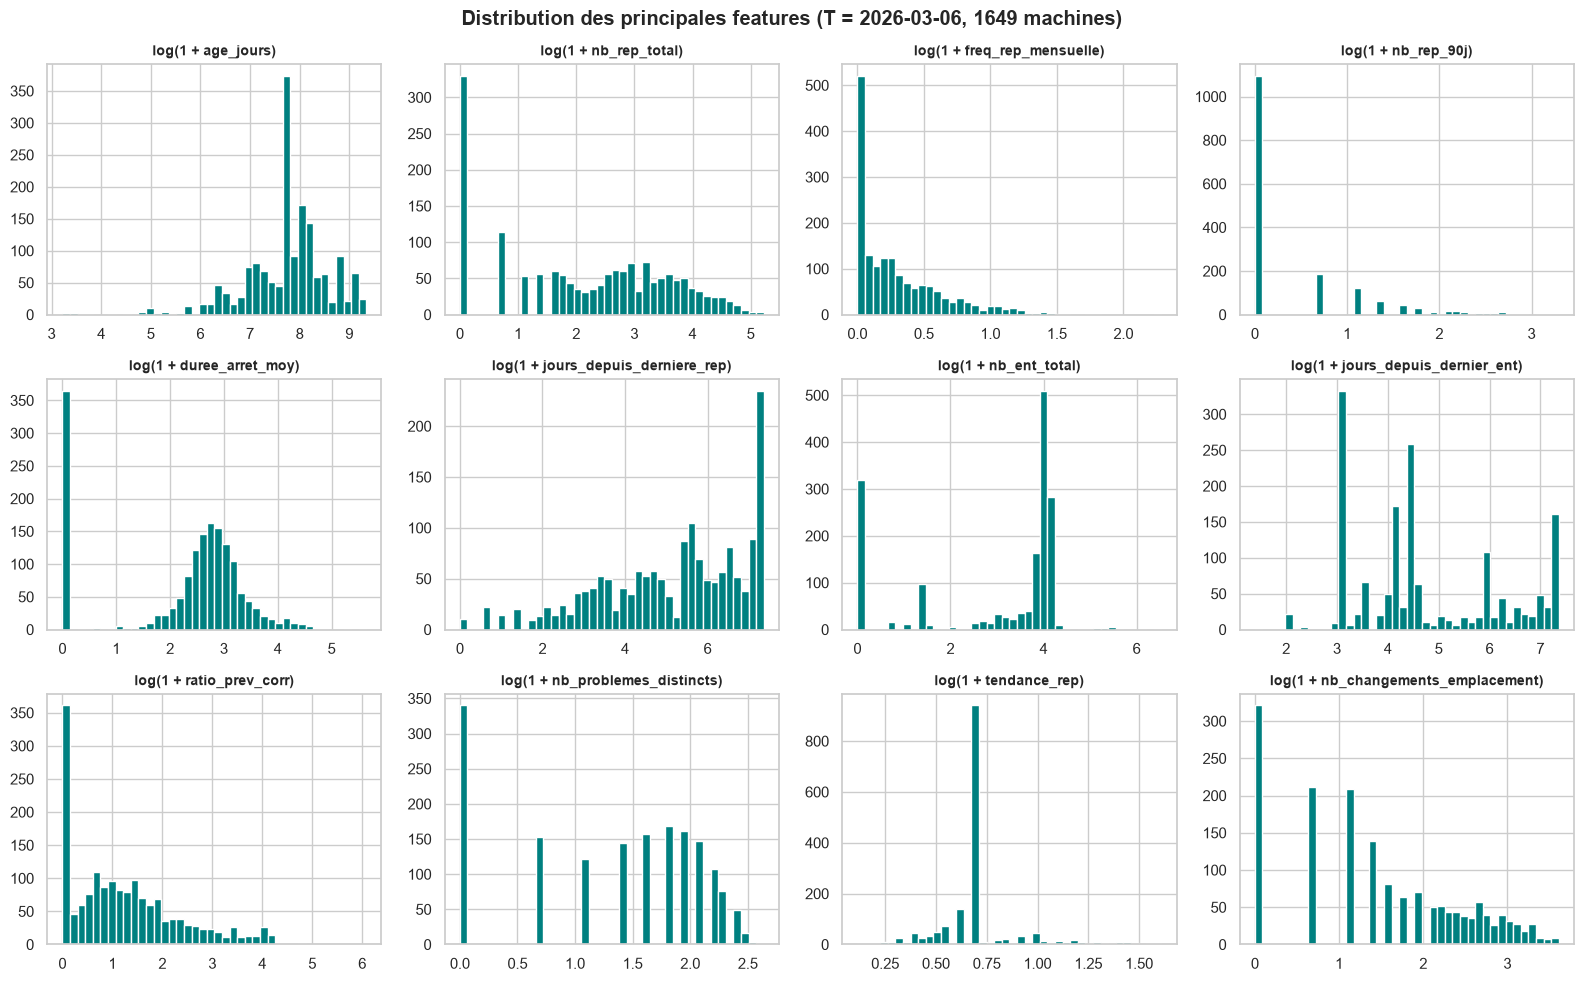

In [39]:
show = ['age_jours', 'nb_rep_total', 'freq_rep_mensuelle', 'nb_rep_90j', 'duree_arret_moy', 'jours_depuis_derniere_rep',
        'nb_ent_total', 'jours_depuis_dernier_ent', 'ratio_prev_corr', 'nb_problemes_distincts', 'tendance_rep', 'nb_changements_emplacement']
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), show):
    ax.hist(np.log1p(snapshot[c].clip(lower=0)), bins=40, color='teal')
    ax.set_title(f'log(1 + {c})', fontsize=10)
plt.suptitle(f'Distribution des principales features (T = {T_REF.date()}, {len(snapshot)} machines)', fontweight='bold')
plt.tight_layout(); plt.show()

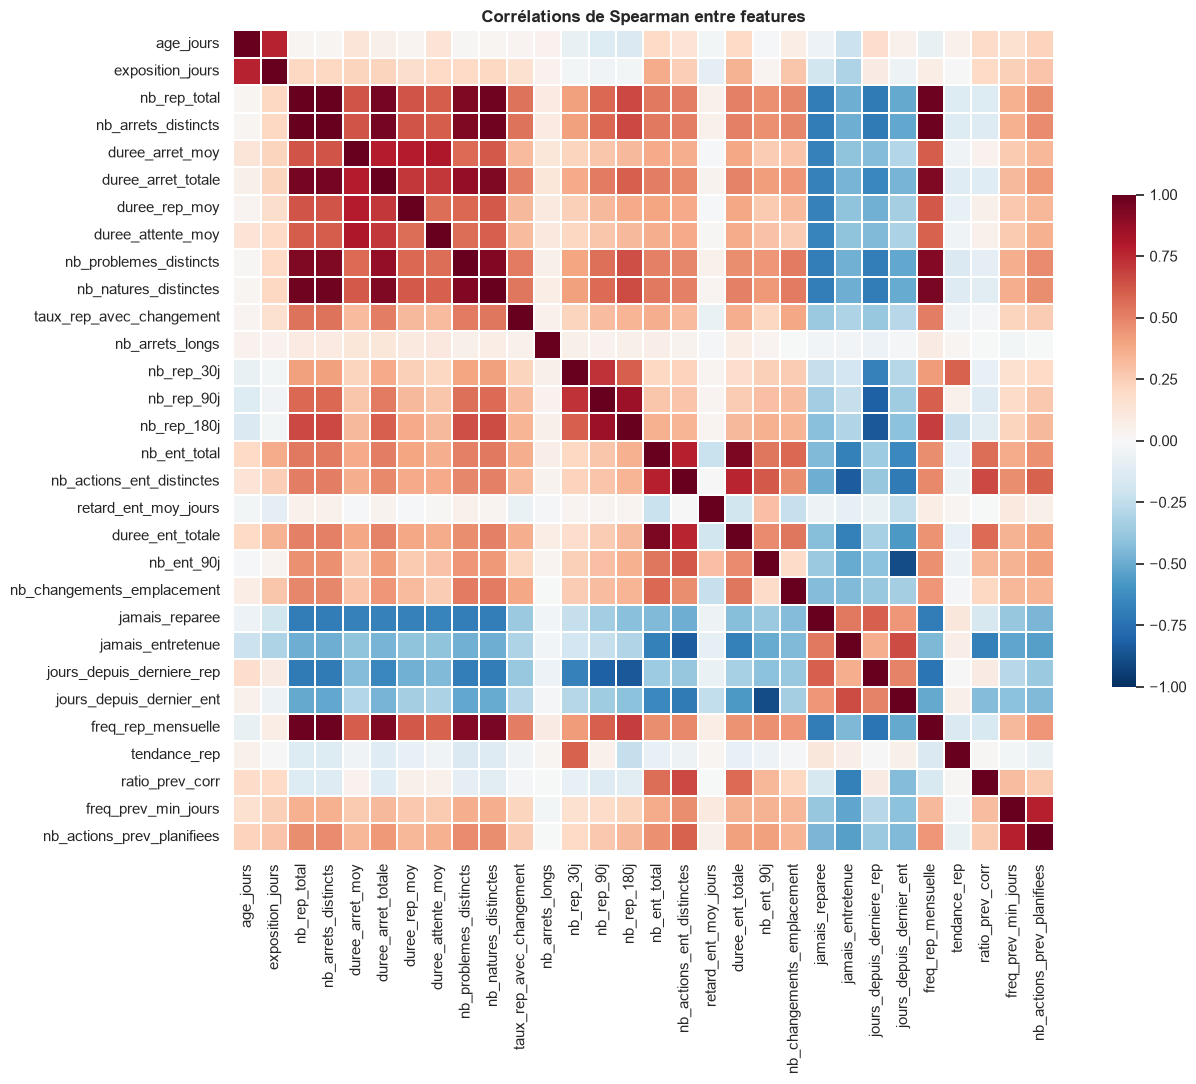

,feature_1,feature_2,spearman
57,nb_rep_total,nb_arrets_distincts,0.999720
105,nb_arrets_distincts,freq_rep_mensuelle,0.979408
79,nb_rep_total,freq_rep_mensuelle,0.979366
63,nb_rep_total,nb_natures_distinctes,0.971110
89,nb_arrets_distincts,nb_natures_distinctes,0.971080
59,nb_rep_total,duree_arret_totale,0.960333
85,nb_arrets_distincts,duree_arret_totale,0.959514
240,nb_natures_distinctes,freq_rep_mensuelle,0.950085
332,nb_ent_total,duree_ent_totale,0.941368
88,nb_arrets_distincts,nb_problemes_distincts,0.936645


In [40]:
corr = snapshot[num_cols].corr(method='spearman')
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, cbar_kws={'shrink': 0.6})
plt.title('Corrélations de Spearman entre features'); plt.tight_layout(); plt.show()

paires = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
          .rename('spearman').reset_index().rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'}))
paires_fortes = paires[paires.spearman.abs() >= 0.9].sort_values('spearman', ascending=False)
paires_fortes

## Étape 6 — Data Leakage

### 6.1 Variables à risque identifiées

### 6.2 Test automatique d'absence de fuite

In [41]:
T_test = pd.Timestamp('2025-01-01')
X_full = build_machine_snapshot(T_test)
X_past = build_machine_snapshot(T_test,
                                rep=reparations[reparations.date_arret < T_test],
                                ent=entretiens[entretiens.date_debut < T_test],
                                hist=historique[historique.date_lecture < T_test])
pd.testing.assert_frame_equal(X_full, X_past)
print(f'OK : à T = {T_test.date()}, les features sont identiques avec ou sans les données futures.')
print('Colonnes instantanées absentes à T passé :', not {'etat_actuel', 'freq_prev_min_jours'} & set(X_full.columns))

OK : à T = 2025-01-01, les features sont identiques avec ou sans les données futures.
Colonnes instantanées absentes à T passé : True


In [42]:
# Démonstration de réutilisation (Partie 2) : panel de snapshots mensuels (machine, T)
dates_T = pd.date_range('2025-01-01', periods=6, freq='MS')
panel = pd.concat([build_machine_snapshot(t) for t in dates_T], ignore_index=True)
print('Panel (machine × date T) :', panel.shape, '| machines distinctes :', panel.id_machine_instance.nunique())
panel.groupby('date_observation')[['nb_rep_30j', 'nb_rep_total', 'nb_ent_90j']].mean().round(2)

Panel (machine × date T) : (9621, 37) | machines distinctes : 1617


,nb_rep_30j,nb_rep_total,nb_ent_90j
date_observation,,,
2025-01-01,0.19,14.84,2.64
2025-02-01,0.22,14.95,2.57
2025-03-01,0.33,15.25,2.45
2025-04-01,0.26,15.50,2.72
2025-05-01,0.40,15.88,2.70
2025-06-01,0.60,16.41,2.51


## Étape 7 — Synthèse : avant / après, datasets produits, limites

### 7.1 Comparaison avant / après préparation

In [43]:
clean = {'machine': machines, 'reparation': reparations, 'appel': appels, 'entretien': entretiens,
         'preventif': preventif, 'historique': historique}
comp = pd.DataFrame([{'table': t,
                      'lignes_avant': len(raw[t]), 'lignes_après': len(clean[t]),
                      'colonnes_avant': raw[t].shape[1], 'colonnes_après': clean[t].shape[1],
                      'cols_vides_avant': int(raw[t].isna().all().sum()), 'cols_vides_après': int(clean[t].isna().all().sum()),
                      'manquants_%_avant': round(raw[t].isna().mean().mean() * 100, 1),
                      'manquants_%_après': round(clean[t].isna().mean().mean() * 100, 1)} for t in clean]).set_index('table')
comp['lignes_supprimées'] = comp.lignes_avant - comp.lignes_après
comp

,lignes_avant,lignes_après,colonnes_avant,colonnes_après,cols_vides_avant,cols_vides_après,manquants_%_avant,manquants_%_après,lignes_supprimées
table,,,,,,,,,
machine,1649,1649,42,20,8,0,30.8,0.2,0
reparation,32772,32772,42,21,3,0,33.1,0.5,0
appel,32331,32331,14,8,4,0,28.8,0.7,0
entretien,65173,63899,18,12,2,0,23.2,1.2,1274
preventif,4109,4109,16,9,5,0,47.8,7.7,0
historique,15191,14654,7,4,2,0,28.6,0.0,537


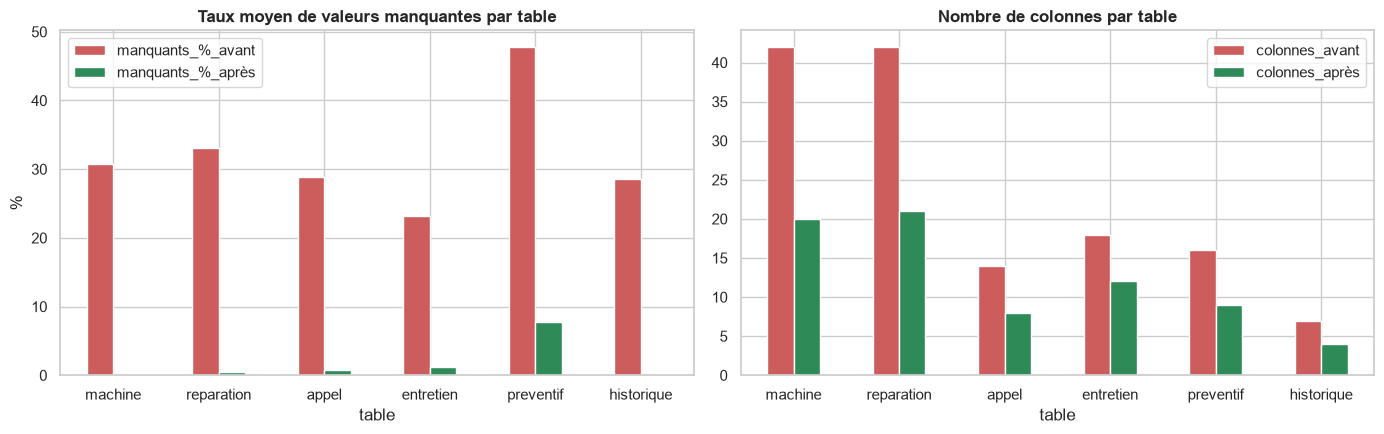

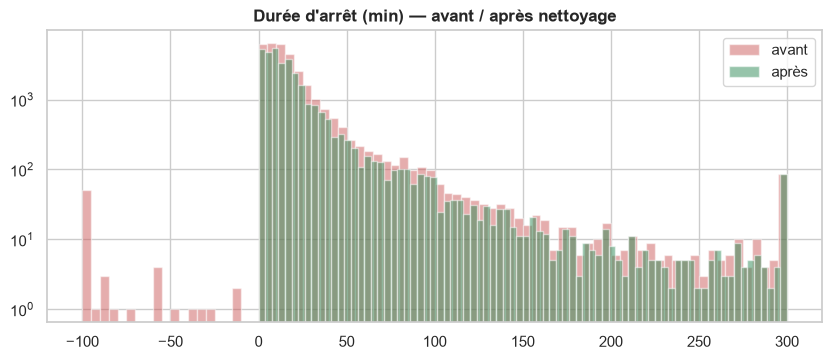

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
comp[['manquants_%_avant', 'manquants_%_après']].plot.bar(ax=axes[0], color=['indianred', 'seagreen'], rot=0)
axes[0].set_title('Taux moyen de valeurs manquantes par table'); axes[0].set_ylabel('%')
comp[['colonnes_avant', 'colonnes_après']].plot.bar(ax=axes[1], color=['indianred', 'seagreen'], rot=0)
axes[1].set_title('Nombre de colonnes par table')
plt.tight_layout(); plt.show()

# Distribution de la durée d'arrêt avant / après (suppression des valeurs impossibles)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(raw['reparation'].dureearret.dropna().clip(-100, 300), bins=80, alpha=0.5, label='avant', color='indianred')
ax.hist(reparations.duree_arret_min.dropna().clip(-100, 300), bins=80, alpha=0.5, label='après', color='seagreen')
ax.set_yscale('log'); ax.set_title('Durée d\'arrêt (min) — avant / après nettoyage'); ax.legend(); plt.show()

### 7.2 Datasets analytiques produits (dossier `Partie1/outputs/`)

In [45]:
EXPORTS = {
    'reparations_enrichies.csv':        (reparations_enrichies, '1 ligne = 1 réparation, décodée (nature, problème, ligne, machine, appel) — base pour S3'),
    'machine_features_snapshot.csv':    (snapshot,              f'1 ligne = 1 machine à T = {T_REF.date()} — base pour U1 / U2 / U3'),
    'machines_clean.csv':               (machines,              '1 ligne = 1 machine (référentiel nettoyé + catégories regroupées)'),
    'entretiens_clean.csv':             (entretiens,            '1 ligne = 1 entretien observé (sans planification future, sans doublons)'),
    'appels_clean.csv':                 (appels,                '1 ligne = 1 appel de panne'),
    'historique_emplacements_clean.csv':(historique,            '1 ligne = 1 lecture datée d\'emplacement'),
    'preventif_clean.csv':              (preventif,             '1 ligne = 1 couple (machine, action préventive)'),
    'dictionnaire_features.csv':        (dictionnaire_features, 'documentation des features'),
    'audit_qualite.csv':                (audit,                 'problèmes de qualité quantifiés + décisions'),
    'journal_transformations.csv':      (pd.DataFrame(LOG),     'traçabilité de toutes les transformations'),
    'paires_features_redondantes.csv':  (paires_fortes,         'paires |Spearman| >= 0,9'),
}
rows = []
for f, (df, desc) in EXPORTS.items():
    df.to_csv(OUT / f, index=False, encoding='utf-8')
    rows.append({'fichier': f, 'lignes': len(df), 'colonnes': df.shape[1], 'description': desc})
pd.DataFrame(rows)

,fichier,lignes,colonnes,description
0,reparations_enrichies.csv,32772,39,"1 ligne = 1 réparation, décodée (nature, problème, ligne, machine,..."
1,machine_features_snapshot.csv,1649,40,1 ligne = 1 machine à T = 2026-03-06 — base pour U1 / U2 / U3
2,machines_clean.csv,1649,20,1 ligne = 1 machine (référentiel nettoyé + catégories regroupées)
3,entretiens_clean.csv,63899,12,"1 ligne = 1 entretien observé (sans planification future, sans dou..."
4,appels_clean.csv,32331,8,1 ligne = 1 appel de panne
5,historique_emplacements_clean.csv,14654,4,1 ligne = 1 lecture datée d'emplacement
6,preventif_clean.csv,4109,9,"1 ligne = 1 couple (machine, action préventive)"
7,dictionnaire_features.csv,25,5,documentation des features
8,audit_qualite.csv,37,5,problèmes de qualité quantifiés + décisions
9,journal_transformations.csv,41,4,traçabilité de toutes les transformations


In [46]:
# Dictionnaire de données du dataset machine (types + manquants)
pd.DataFrame({'type': snapshot.dtypes.astype(str), 'manquants': snapshot.isna().sum(),
              'exemple': snapshot.iloc[0]}).T

,id_machine_instance,date_observation,categorie_grp,fabricant_grp,designation_grp,methode_grp,moteur,id_site,age_jours,exposition_jours,nb_rep_total,nb_arrets_distincts,duree_arret_moy,duree_arret_totale,duree_rep_moy,duree_attente_moy,nb_problemes_distincts,nb_natures_distinctes,taux_rep_avec_changement,nb_arrets_longs,nb_rep_30j,nb_rep_90j,nb_rep_180j,nb_ent_total,nb_actions_ent_distinctes,retard_ent_moy_jours,duree_ent_totale,nb_ent_90j,nb_changements_emplacement,type_endroit_T,jamais_reparee,jamais_entretenue,jours_depuis_derniere_rep,jours_depuis_dernier_ent,freq_rep_mensuelle,tendance_rep,ratio_prev_corr,etat_actuel,freq_prev_min_jours,nb_actions_prev_planifiees
type,int64,datetime64[ns],string,string,string,string,string,int64,int64,int64,int64,int64,float64,int64,float64,float64,int64,int64,float64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,string,int64,int64,float64,float64,float64,float64,float64,string,float64,int64
manquants,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
exemple,814,2026-03-06 00:00:00,MACHINE A COUDRE,YAMATO,FLATLOCK,FLAT,ECONOMIQUE,1,2356,1574,36,34,25.942857,908,12.027778,16.424242,6,9,0.114286,0,1,1,9,55,3,-1.211538,341,2,10,PARC,0,0,10.0,59.0,0.696213,0.8,1.486486,EN BON ETAT,28.0,3


### 7.3 Limites connues des données

### 7.4 Risques de Data Leakage (récapitulatif)

### 7.5 Conclusion